# 16_3 · G/F con crecimiento por azúcar disponible e identificabilidad

Ambas simulaciones usan los parámetros químicos guardados del 16_2, sus pulsos, sus entradas de temperatura, sus condiciones iniciales y su capa de CO₂. La variante del EKF 16 permite que el crecimiento y la captación de YAN continúen mientras quede glucosa o fructosa. Cada azúcar agotado deja de aportar al crecimiento. Se compara una sola modificación de la dinámica en LAB004–009 y LAB016–024.

In [1]:
from pathlib import Path
from types import FunctionType
import json

import nbformat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/wine_fermentation").is_dir())
source, = (ROOT / "notebooks").glob("16_2_*.source.ipynb")
calibration = nbformat.read(source, 4)
saved = nbformat.read(source.with_name(source.name.replace(".source.", ".executed.")), 4)
assert [cell.source for cell in calibration.cells] == [cell.source for cell in saved.cells]
[output] = [o.text.split("PARÁMETROS QUÍMICOS COMPLETOS", 1)[1].lstrip()
            for o in saved.cells[5].outputs
            if o.output_type == "stream" and "PARÁMETROS QUÍMICOS COMPLETOS" in o.text]
theta, _ = json.JSONDecoder().raw_decode(output)

def reference(index, start=None, stop=None):
    code = calibration.cells[index].source
    if start is not None:
        assert code.count(start) == 1
        code = code[code.index(start):]
    if stop is not None:
        assert code.count(stop) == 1
        code = code[:code.index(stop)]
    return code

setup = {"__name__": "__main__", "display": lambda *_: None}
for code in (reference(1, stop="start=kin.normalize_parameters"),
             reference(3),
             reference(12, stop="cores,caches,activation=build_curves(theta)"),
             reference(12, start="KLA, GAIN =", stop="curves={lab:gas(lab,KLA,GAIN)"),
             reference(13)):
    exec(compile(code, source.name, "exec"), setup)
kin = setup["kin"]
assert set(theta) == set(kin.PARAMETERS)
display(pd.Series(theta, name="Parámetros guardados del 16_2"))
print("Capa de CO₂ del 16_2", setup["HOLDOUT_GAS_PARAMS"])

,LAB,original_g_L,viables_millones_mL,corregido_g_L
0,LAB004,0.3939,10.75,0.3225
1,LAB005,0.4932,11.25,0.3375


Pares de réplicas: 23 sigma réplica: 0.1189341469231937 sigmaX de referencia del 16: 0.5


,LAB,agotamiento_h,corte_YAN_h,N0_mg,pulsos,X,N,G,F,E
0,LAB004,91.0,103.0,230.76,"((68.5, 0.08),)",10,8,12,12,4
1,LAB005,91.0,103.0,227.30,"((68.5, 0.08),)",10,8,12,12,4
2,LAB006,122.0,134.0,229.12,"((100.0, 0.08),)",12,9,14,14,4
3,LAB007,88.0,100.0,239.04,"((65.5, 0.08),)",11,8,12,12,5
4,LAB008,88.0,100.0,239.22,"((65.5, 0.08),)",11,8,12,12,5
5,LAB009,64.0,76.0,237.40,"((41.84615384615385, 0.08),)",10,6,11,11,4


,LAB,t_h,original_mg,usado_mg,estado
0,LAB004,0.0,230.76,230.76,Inicial
1,LAB004,19.0,182.72,182.72,Usado
2,LAB004,26.0,157.42,157.42,Usado
3,LAB004,43.0,60.16,60.16,Usado
4,LAB004,50.0,19.00,0.00,Transformado
...,...,...,...,...,...
74,LAB009,88.0,17.00,NaN,Excluido
75,LAB009,96.0,19.00,NaN,Excluido
76,LAB009,120.0,5.00,NaN,Excluido
77,LAB009,144.0,25.00,NaN,Excluido


Observaciones en el objetivo {'X': 64, 'N': 47, 'G': 73, 'F': 73, 'E': 26}


,LAB,X,N,G,F,E,pulsos,corte_h
0,LAB019,0.283162,0.230025,79.190000,78.970000,12.075372,"((64.33333333333277, 0.08648648648648648),)",166.000000
1,LAB020,0.153342,0.225556,77.940000,79.520000,11.917524,"((71.66666666666694, 0.08888888888888889),)",172.333333
2,LAB021,0.270000,0.231202,80.190000,81.040000,11.759676,"((47.5, 0.08648648648648648),)",166.000000
3,LAB016,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93555555555583, 0.14),)",151.100000
4,LAB017,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.933611111110835, 0.28),)",141.000000
5,LAB018,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93166666666694, 0.14),)",141.000000


,Pulso [h],Volumen [L],Aporte [mg N/L]
LAB,,,
LAB022,113.633,1.85,99.906
LAB023,113.783,1.85,99.906
LAB024,113.883,1.85,99.906


mu0         0.086722
betaG0      0.428291
betaF0      0.593521
Kn0         0.008258
Kg0         4.400775
Kf0        19.296084
Kig0       80.490799
Kie0      168.120412
Kd0         0.000440
Yxn         5.272368
Yxg         0.966094
Yxf         1.109896
Yeg         0.459547
Yef         0.510598
m0          0.018339
Name: Parámetros guardados del 16_2, dtype: float64

Capa de CO₂ del 16_2 (0.15007991020720535, 0.6460643588058115)


## Integración y regla de crecimiento

Se localiza cuándo cada azúcar llega a cero y se integra de nuevo desde ese punto. El mismo manejo de eventos se usa en ambas simulaciones. En la producción de CO₂, el aporte de crecimiento sigue la misma regla que los balances químicos.

In [2]:
BASE = "Regla del 16_2"
AVAILABLE = "Regla del EKF 16"
LABELS = (BASE, AVAILABLE)
SUGARS = np.array([2, 3])
solve_ivp = setup["solve_ivp"]

def integrate_sugar_events(rhs, interval, initial, *, t_eval, **options):
    start, end = interval
    state = np.array(initial, copy=True)
    active = list(SUGARS[state[SUGARS] > 0.])
    pieces_t, pieces_y = [], []
    remaining = np.asarray(t_eval)
    while start < end:
        frozen = list(set(SUGARS) - set(active))

        def stage_rhs(t, y):
            physical = y.copy()
            physical[active] = np.maximum(physical[active], np.finfo(float).tiny)
            physical[frozen] = 0.
            derivative = rhs(t, physical)
            derivative[frozen] = 0.
            return derivative

        events = []
        for index in active:
            def depleted(t, y, index=index):
                return y[index]
            depleted.terminal = True
            depleted.direction = -1
            events.append(depleted)

        result = solve_ivp(stage_rhs, (start, end), state, t_eval=remaining,
                           events=events or None, **options)
        if not result.success:
            return result
        pieces_t.append(np.asarray(result.t))
        pieces_y.append(np.asarray(result.y).reshape(len(initial), -1))
        if result.status != 1:
            break
        [hit] = [i for i, times in enumerate(result.t_events) if len(times)]
        start = result.t_events[hit][0]
        state = result.y_events[hit][0].copy()
        state[active.pop(hit)] = 0.
        remaining = remaining[remaining > start]

    result.t = np.concatenate(pieces_t)
    result.y = np.concatenate(pieces_y, axis=1)
    np.testing.assert_array_equal(result.t, t_eval)
    return result

# Mantener el integrador, los pulsos y los tiempos de evaluación del 16_2.
simulate_source = reference(3, start="def simulate(b,p):", stop="def with_jumps")
old_guard = simulate_source[simulate_source.index("  if y[2]<=0 or y[3]<=0:"):
                            simulate_source.index("  return out")]
new_guard = '''  if y[2]<=0 or y[3]<=0:
   q=kin.kinetic_terms(p,kin.temperature_at(b,t),*y);growth=q['mu']*max(float(y[0]),0)
   if y[2]<=0 and y[3]<=0:
    out[0]-=growth;out[1]+=growth/p['Yxn']
   if y[2]<=0:
    out[2]+=growth/p['Yxg']
   if y[3]<=0:
    out[3]+=growth/p['Yxf']
'''
holdout_source = reference(14, start="def run_holdout(theta):",
                           stop="holdout_kinetic, holdout_plot, holdout_gas, holdout_mean_gas = run_holdout(theta)")
historical_source = reference(12, start="def build_curves(parameters):", stop="PCO2_BAR=1.0")

training = {batch.batch: batch for batch in setup["treated"]}
historical = setup["batches"]
recent = setup["holdout_batches"]
batches = {**training, **historical, **recent}
assert set(batches) == {f"LAB{n:03}" for n in (*range(4, 10), *range(16, 25))}
trajectories, gas_curves, recent_gas, training_raw = {}, {}, {}, {}

for label in LABELS:
    context = {**setup, "solve_ivp": integrate_sugar_events}
    for name in ("configure_gas", "gas"):
        function = setup[name]
        context[name] = FunctionType(function.__code__, context, argdefs=function.__defaults__)
    chemistry, history, holdout = simulate_source, historical_source, holdout_source
    if label == AVAILABLE:
        assert chemistry.count(old_guard) == 1
        chemistry = chemistry.replace(old_guard, new_guard)
        history = history.replace("y[2]<=0 or y[3]<=0", "y[2]<=0 and y[3]<=0")
        holdout = holdout.replace("y[2] > 0 and y[3] > 0", "y[2] > 0 or y[3] > 0")

    exec(compile(chemistry + history + holdout, source.name, "exec"), context)
    context["simulate_holdout"] = context["simulate"]
    training_raw[label] = {lab: context["simulate"](batch, theta) for lab, batch in training.items()}
    cores, caches, activation = context["build_curves"](theta)
    context.update(caches=caches, activation=activation)
    context["configure_gas"](cores)
    gas_curves[label] = {lab: context["gas"](lab, *setup["HOLDOUT_GAS_PARAMS"]) for lab in historical}
    holdout_cores, _, holdout_gas, recent_gas[label] = context["run_holdout"](theta)
    gas_curves[label].update(holdout_gas)
    trajectories[label] = {**training_raw[label], **cores, **holdout_cores}

# Verificar condiciones iniciales, pulsos y mallas comunes.
for lab, batch in batches.items():
    a, b = (trajectories[label][lab] for label in LABELS)
    np.testing.assert_array_equal(a.index, b.index)
    np.testing.assert_array_equal(a.iloc[0], b.iloc[0])
    for frame in (a, b):
        assert (frame.to_numpy() >= 0.).all()
        received = [(j["t"], j["after"][1] - j["before"][1]) for j in frame.attrs["pulse_jumps"]]
        np.testing.assert_allclose(received, batch.pulses["N"], atol=1e-12, rtol=0.)
    # Las curvas deben coincidir antes de que se agote el primer azúcar.
    both = (a.G > 0.) & (a.F > 0.)
    stops = np.flatnonzero(~both.to_numpy())
    last = stops[0] if len(stops) else len(a)
    np.testing.assert_allclose(a.iloc[:last], b.iloc[:last], atol=2e-7, rtol=2e-6)

print(f"{len(batches)} lotes y {len(batches) * len(LABELS)} simulaciones químicas verificadas.")

15 lotes y 30 simulaciones químicas verificadas.


## Residuos y agotamiento de azúcar

En LAB004–009 se usa el soporte y la ponderación del objetivo histórico. Los RMSE químicos excluyen la condición inicial. Para LAB016–018, la referencia de G+F procede de densidad. En LAB022–024, el flujo de CO₂ se compara en medias de 30 minutos y conserva los huecos de la medición.

In [3]:
VARS = {
    "X": ("Biomasa viable", "g/L", 1.), "N": ("YAN", "mg N/L", 1000.),
    "G": ("Glucosa", "g/L", 1.), "F": ("Fructosa", "g/L", 1.),
    "GF": ("G+F", "g/L", 1.), "E": ("Etanol", "g/L", 1.),
    "CO2": ("Flujo de CO₂", "g/(L·h)", 1.),
}
recent_columns = {"X": ("holdout_biomass", "X_g_L"), "N": ("holdout_chemistry", "YAN for plot"),
                  "G": ("holdout_chemistry", "GLUCOSE-320"), "F": ("holdout_chemistry", "Fructose (derived)"),
                  "GF": ("holdout_chemistry", "GLU-FRU-320")}
v = setup["v"]

def observed(lab, state):
    batch = batches[lab]
    factor = VARS[state][2]
    horizon = v.horizons[lab] if lab in historical else batch.time[-1]
    if lab in training:
        if state == "CO2":
            return pd.Series(dtype=float)
        values = batch.observations["G"] + batch.observations["F"] if state == "GF" else batch.observations[state]
        times = batch.time
        values = factor * values
    elif state == "CO2":
        if lab in recent:
            common_windows = recent_gas[BASE][lab].index
            return setup["holdout_flow"][lab].reindex(common_windows).dropna()
        frame = setup["obs"][lab]
        times, values = frame.time_h.to_numpy(), frame.co2_raw_g_l_h.to_numpy()
    elif lab in recent:
        if state not in recent_columns:
            return pd.Series(dtype=float)
        table, column = recent_columns[state]
        frame = setup[table]
        samples = frame.loc[frame.lab.eq(lab) & frame["sample"].ne("01")]
        times, values = samples.hours.to_numpy(), samples[column].to_numpy()
    elif lab in setup["TRAIN"]:
        frame = setup["chemical_observations"](v.chem, lab, state)
        times, values = frame.t_h.to_numpy(), factor * frame[setup["CHEMICAL_COLUMNS"][state]].to_numpy()
    elif state == "X":
        frame = v.biomass.loc[v.biomass.lab.eq(lab)]
        times, values = frame.t_h.to_numpy(), frame.X_viable_g_l.to_numpy()
    elif state == "GF":
        frame = v.density.loc[v.density.lab.eq(lab)]
        times, values = frame.t_h.to_numpy(), 2.5 * (frame.density_g_l.to_numpy() - 1000.)
    else:
        return pd.Series(dtype=float)
    mask = np.isfinite(values) & (times > batch.time[0]) & (times <= horizon)
    return pd.Series(values[mask], index=times[mask]).sort_index()

def predicted(label, lab, state, *, plot=False):
    if state == "CO2":
        return recent_gas[label][lab] if lab in recent else gas_curves[label][lab]["qpred"]
    frame = trajectories[label][lab]
    if plot:
        frame = setup["with_jumps"](frame)
    return VARS[state][2] * frame[state]

samples = {(lab, state): observed(lab, state) for lab in batches for state in VARS}
rows = []
for (lab, state), obs in samples.items():
    if obs.empty:
        continue
    row = {"LAB": lab, "Variable": state, "n": len(obs)}
    for label in LABELS:
        pred = predicted(label, lab, state)
        errors = np.interp(obs.index, pred.index, pred.values) - obs.values
        row[label] = np.sqrt(np.mean(errors**2))
    row["Δ RMSE"] = row[AVAILABLE] - row[BASE]
    rows.append(row)
rmse = pd.DataFrame(rows).set_index(["LAB", "Variable"])
display(rmse.round(4))

weighted = {}
for label in LABELS:
    residuals = [(trajectories[label][b.batch][state].to_numpy()[mask] - b.observations[state][mask])
                 / setup["sigma"](state, b.observations[state][mask])
                 for b, state, mask in setup["support"]]
    weighted[label] = np.mean(np.concatenate(residuals)**2)
print("MSE ponderado LAB004–009:", weighted)
np.testing.assert_allclose(weighted[BASE], 4.715502281177189, rtol=2e-5)

summary = []
for lab, batch in batches.items():
    a, b = (trajectories[label][lab] for label in LABELS)
    delta = (a - b).abs().max()
    row = {"LAB": lab, "Δ máximo X [g/L]": delta.X, "Δ máximo N [mg N/L]": 1000 * delta.N}
    for label, frame in zip(LABELS, (a, b)):
        first = frame.index[(frame.G <= 1e-8) | (frame.F <= 1e-8)]
        row[f"Primer azúcar agotado [h] · {label}"] = first[0] if len(first) else np.nan
        row[f"YAN final [mg N/L] · {label}"] = 1000 * frame.N.iloc[-1]
    summary.append(row)
summary = pd.DataFrame(summary).set_index("LAB")
display(summary.round(4))
print(summary.round(4).to_string())
print(rmse.loc[["LAB022", "LAB023", "LAB024"]].round(4).to_string())

n  Regla del 16_2  Regla del EKF 16  Δ RMSE
LAB    Variable                                               
LAB004 X          10          0.2316            0.2316  0.0000
       N           8         28.2940           28.2940  0.0000
       G          12          3.5450            3.5450  0.0000
       F          12          7.0687            7.0687  0.0000
       GF         12         10.5070           10.5070  0.0000
...              ...             ...               ...     ...
LAB024 N           6         77.4098           80.3601  2.9502
       G           5          8.6883            8.6883  0.0000
       F           5         11.9049           12.0053  0.1004
       GF          5         18.8707           18.9449  0.0742
       CO2       378          0.1765            0.1765  0.0001

[84 rows x 4 columns]

MSE ponderado LAB004–009: {'Regla del 16_2': 4.715502281177189, 'Regla del EKF 16': 4.715502281177189}


,Δ máximo X [g/L],Δ máximo N [mg N/L],Primer azúcar agotado [h] · Regla del 16_2,YAN final [mg N/L] · Regla del 16_2,Primer azúcar agotado [h] · Regla del EKF 16,YAN final [mg N/L] · Regla del EKF 16
LAB,,,,,,
LAB004,0.0000,0.0000,NaN,0.0000,NaN,0.0
LAB005,0.0000,0.0000,NaN,0.0000,NaN,0.0
LAB006,0.0000,0.0000,NaN,0.0000,NaN,0.0
LAB007,0.0000,0.0000,NaN,0.0000,NaN,0.0
LAB008,0.0000,0.0000,NaN,0.0000,NaN,0.0
LAB009,0.0000,0.0000,146.0000,0.0000,146.0000,0.0
LAB019,0.0000,0.0000,178.0833,0.0000,178.0833,0.0
LAB020,0.0000,0.0000,NaN,0.0000,NaN,0.0
LAB021,0.0000,0.0000,163.0833,0.0000,163.0833,0.0


        Δ máximo X [g/L]  Δ máximo N [mg N/L]  Primer azúcar agotado [h] · Regla del 16_2  YAN final [mg N/L] · Regla del 16_2  Primer azúcar agotado [h] · Regla del EKF 16  YAN final [mg N/L] · Regla del EKF 16
LAB                                                                                                                                                                                                                
LAB004            0.0000               0.0000                                         NaN                               0.0000                                           NaN                                    0.0
LAB005            0.0000               0.0000                                         NaN                               0.0000                                           NaN                                    0.0
LAB006            0.0000               0.0000                                         NaN                               0.0000                          

## Trayectorias de los dos modelos

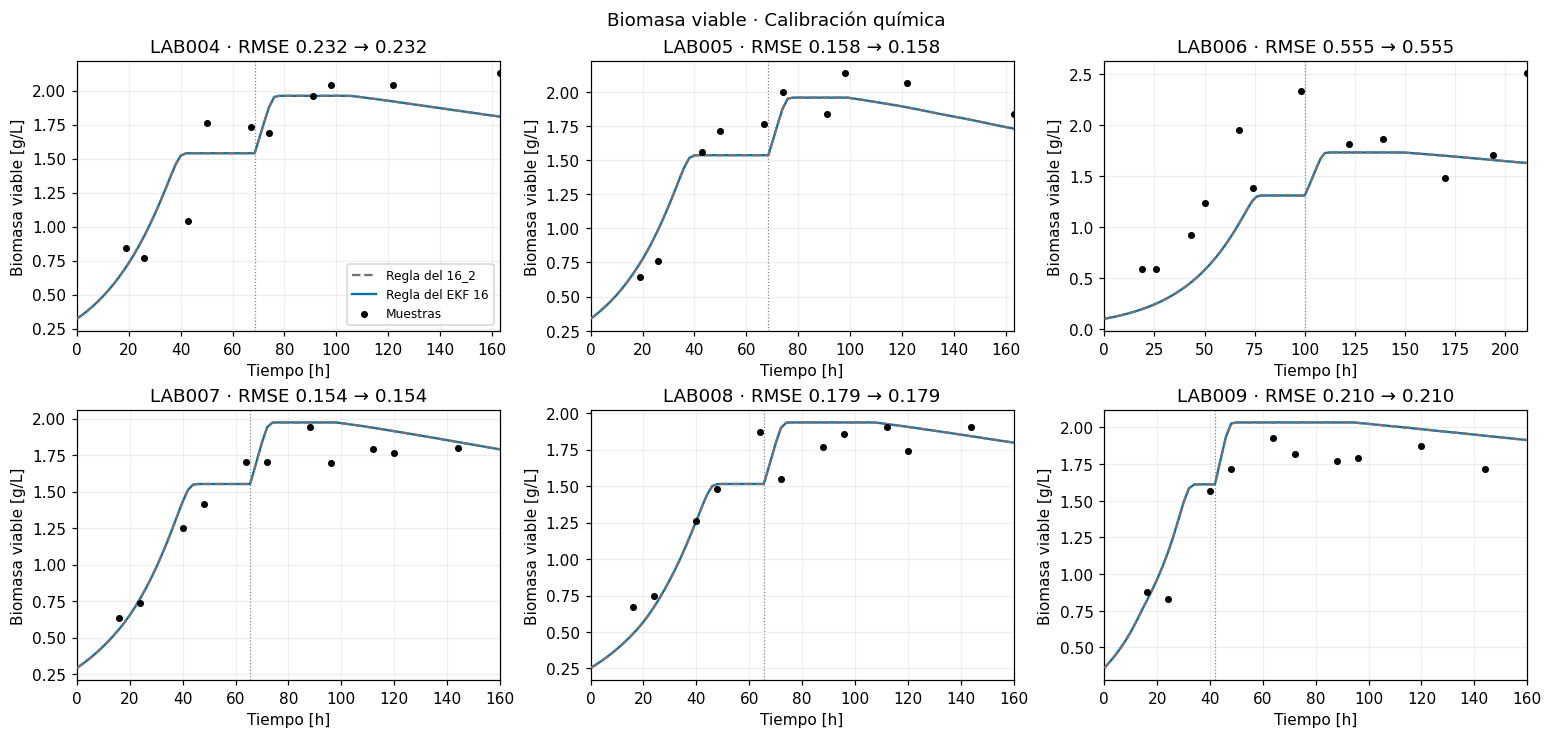

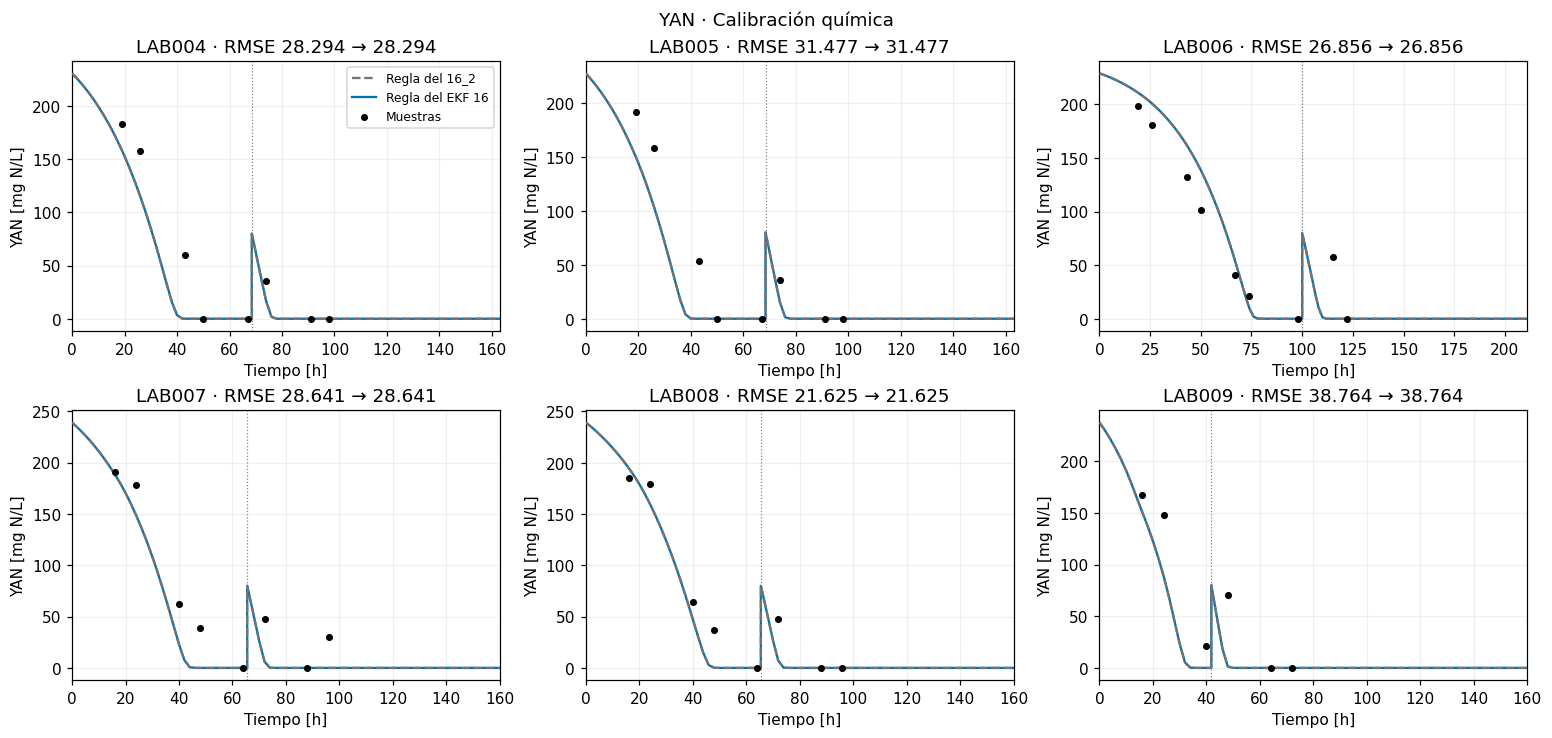

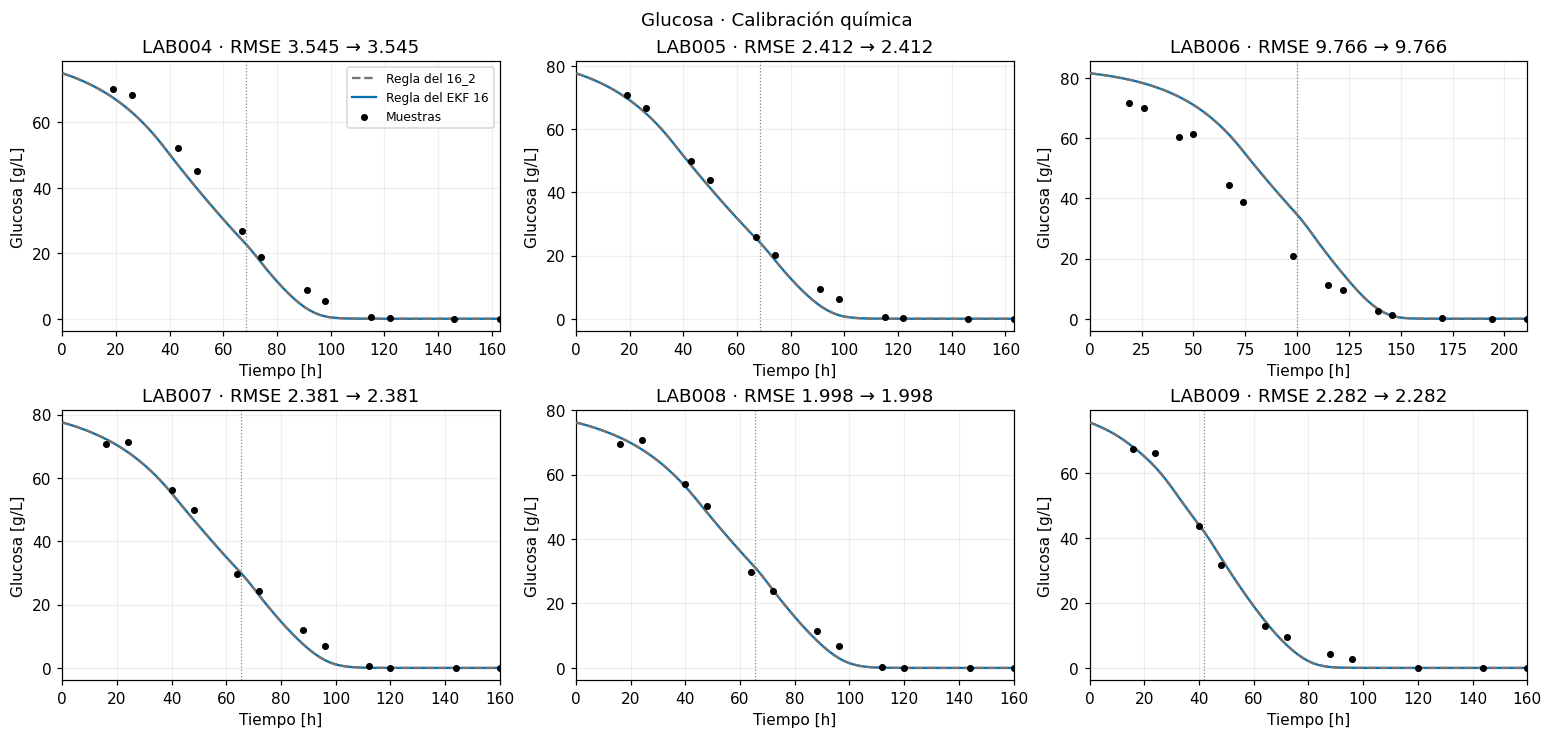

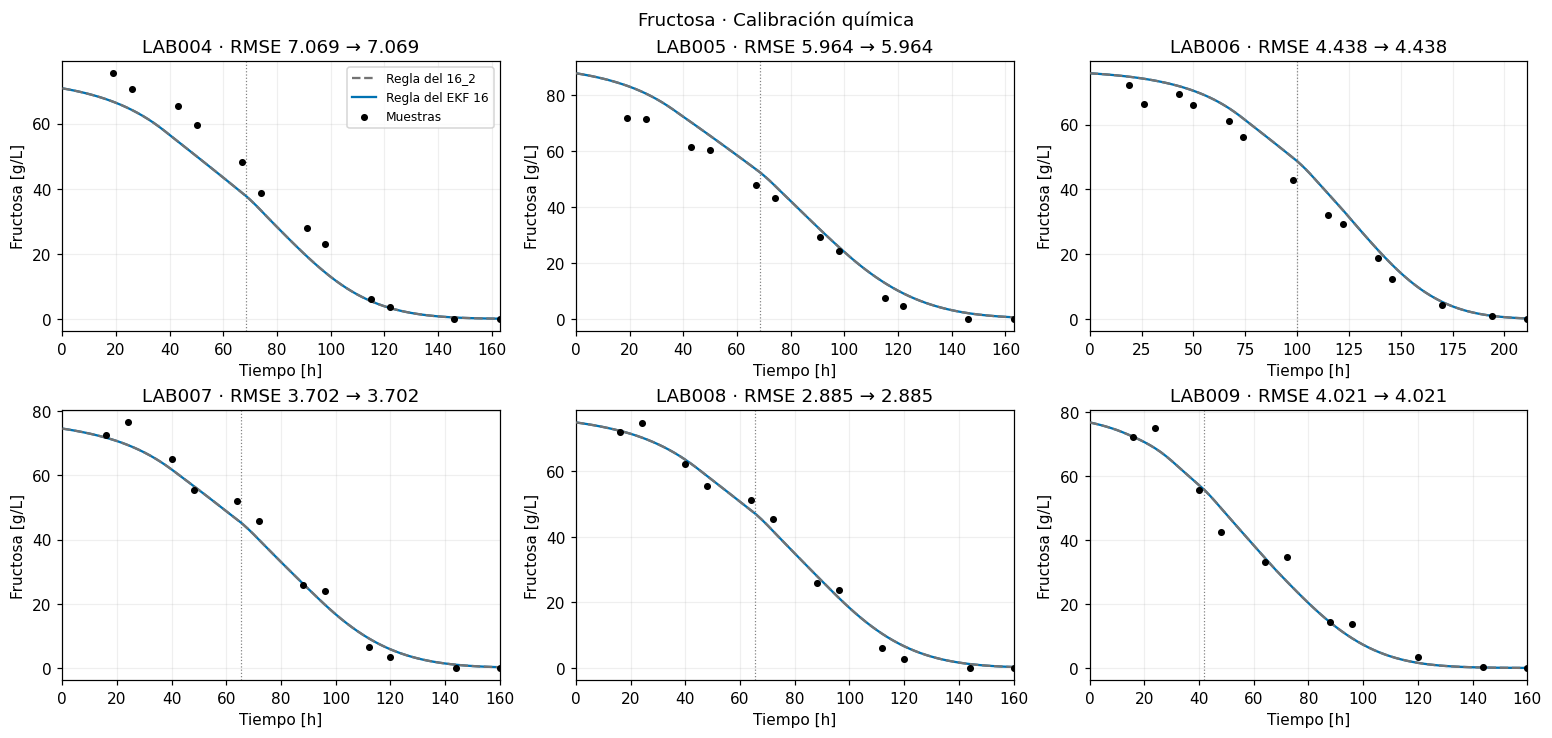

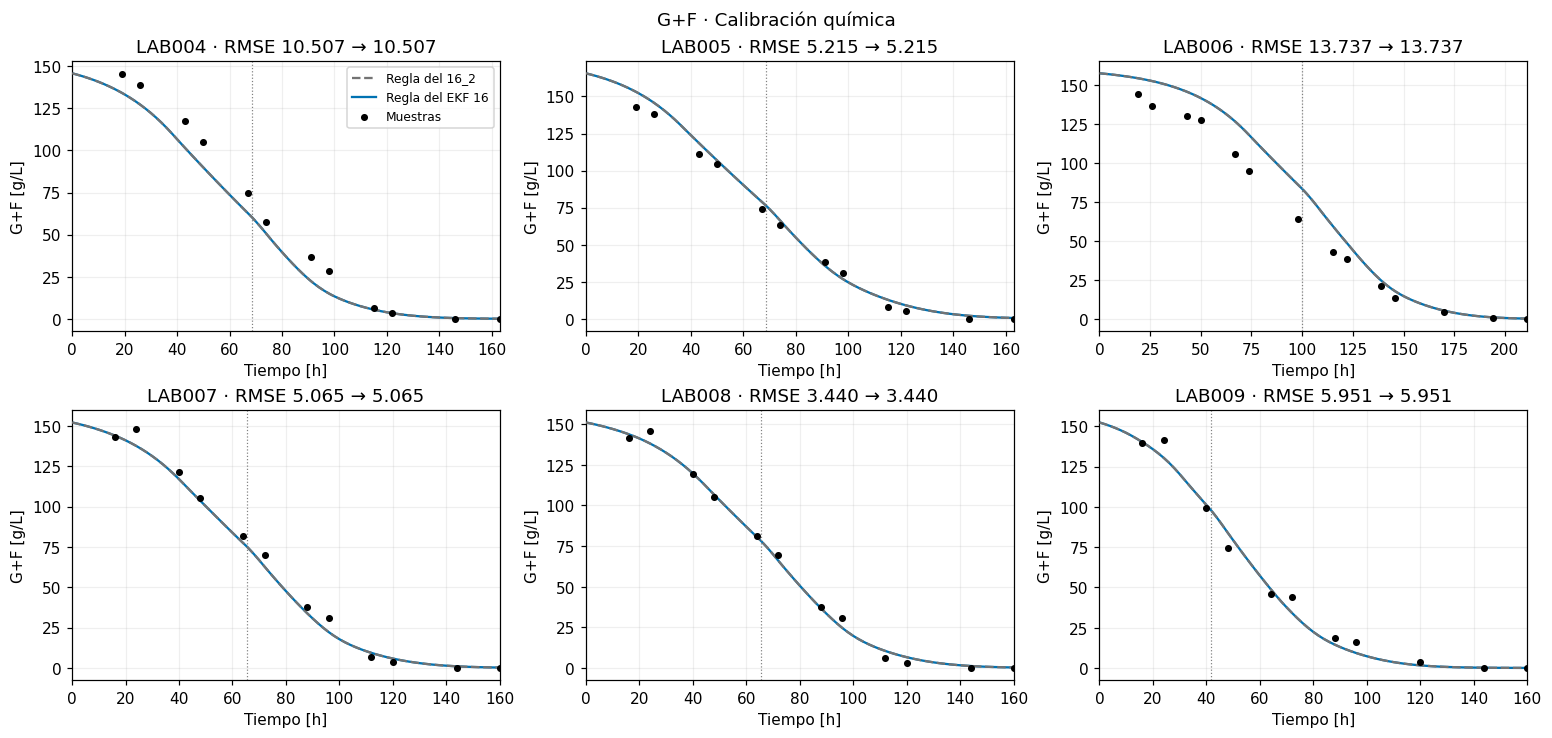

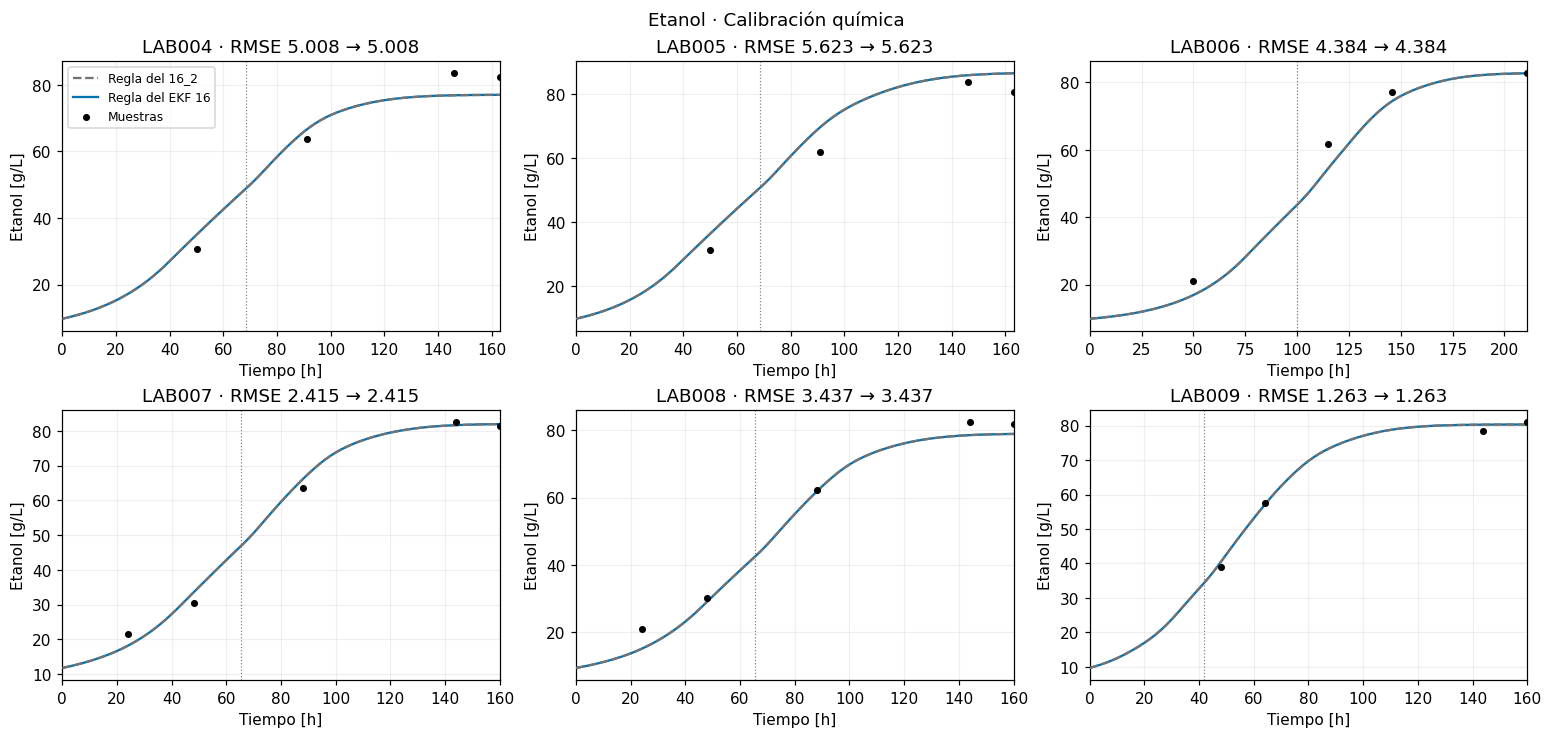

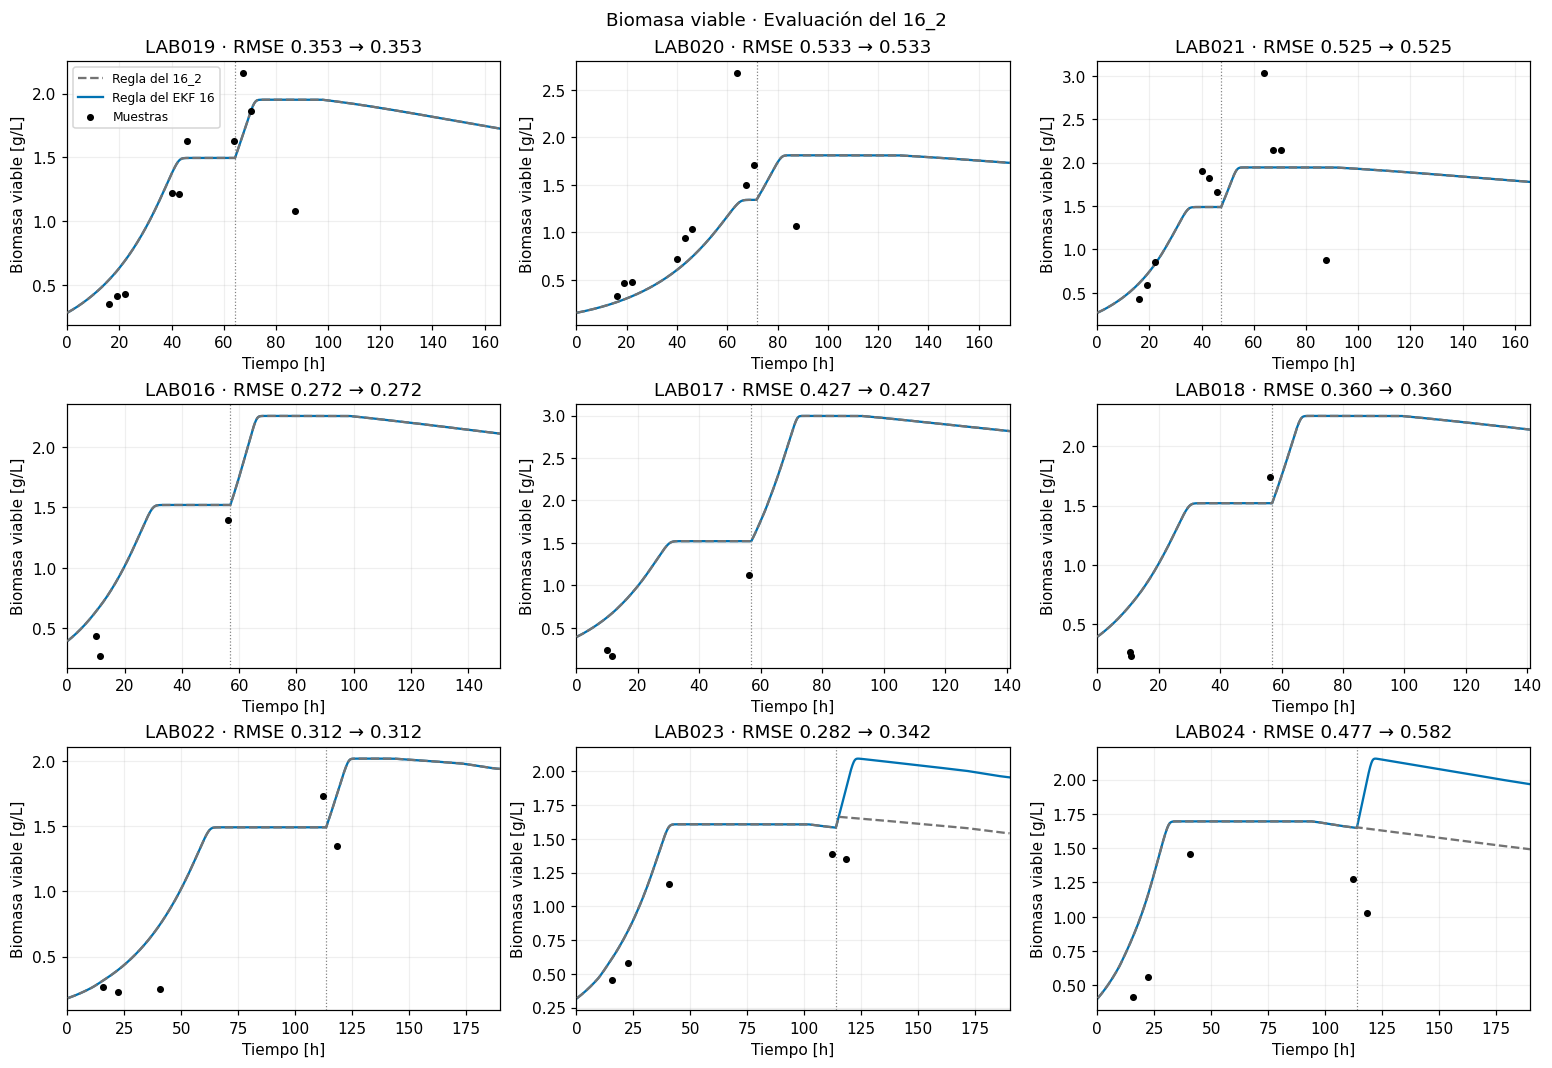

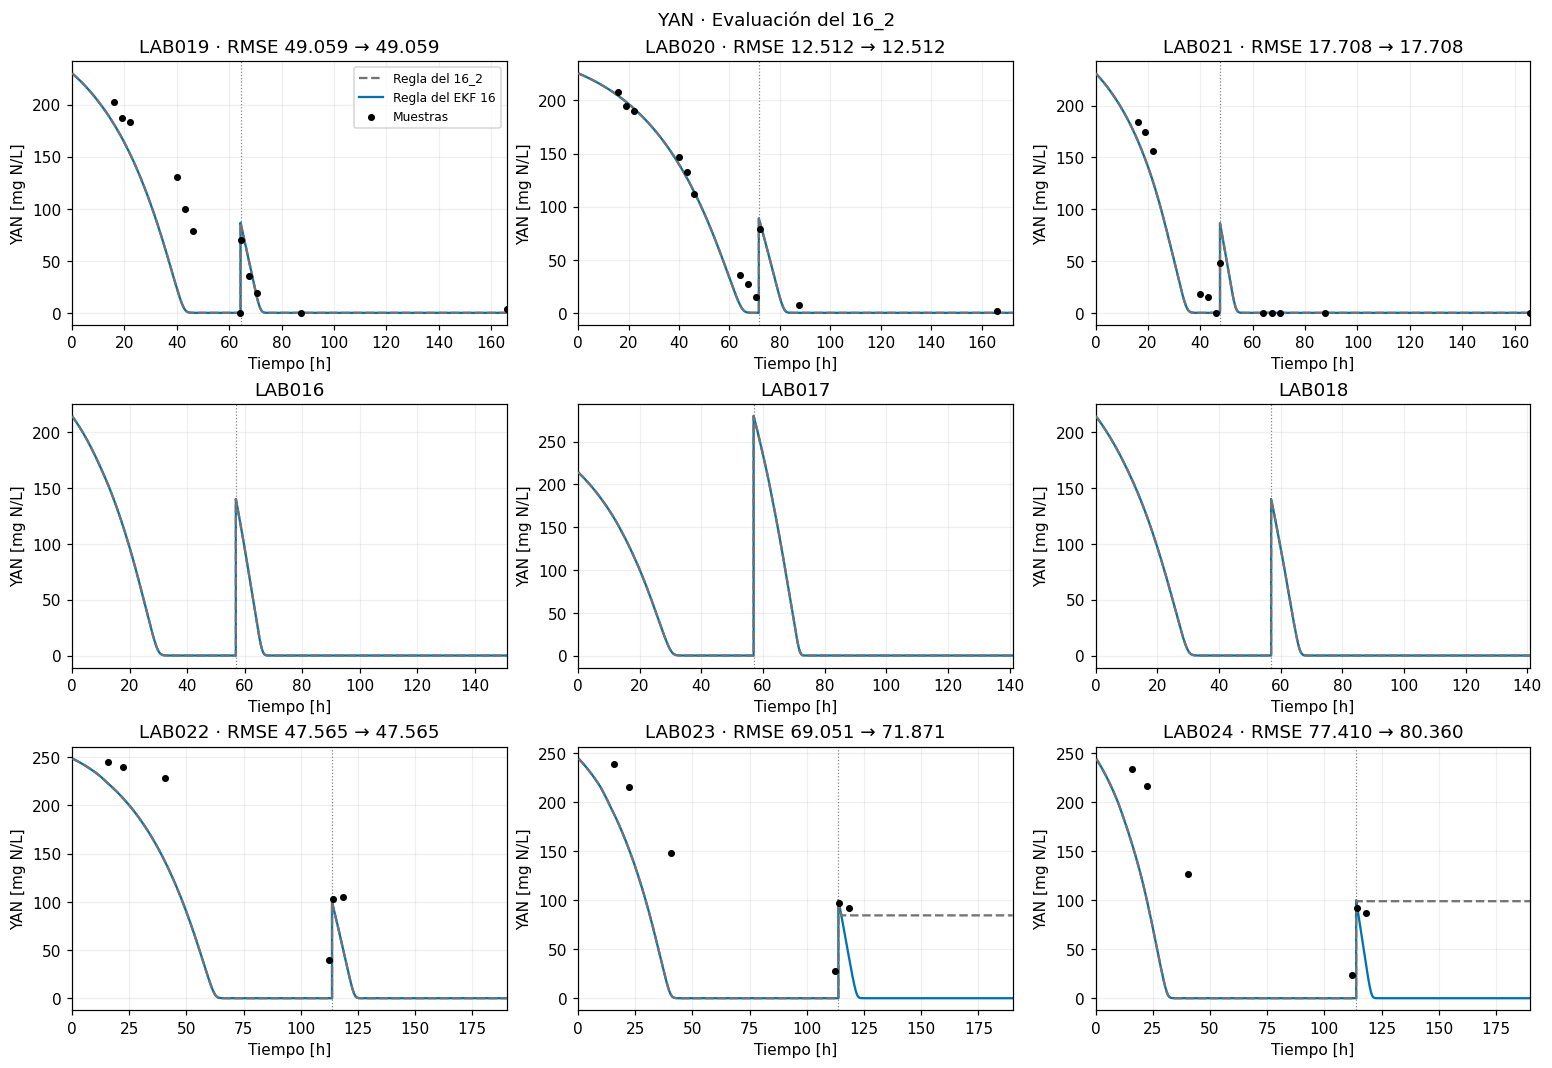

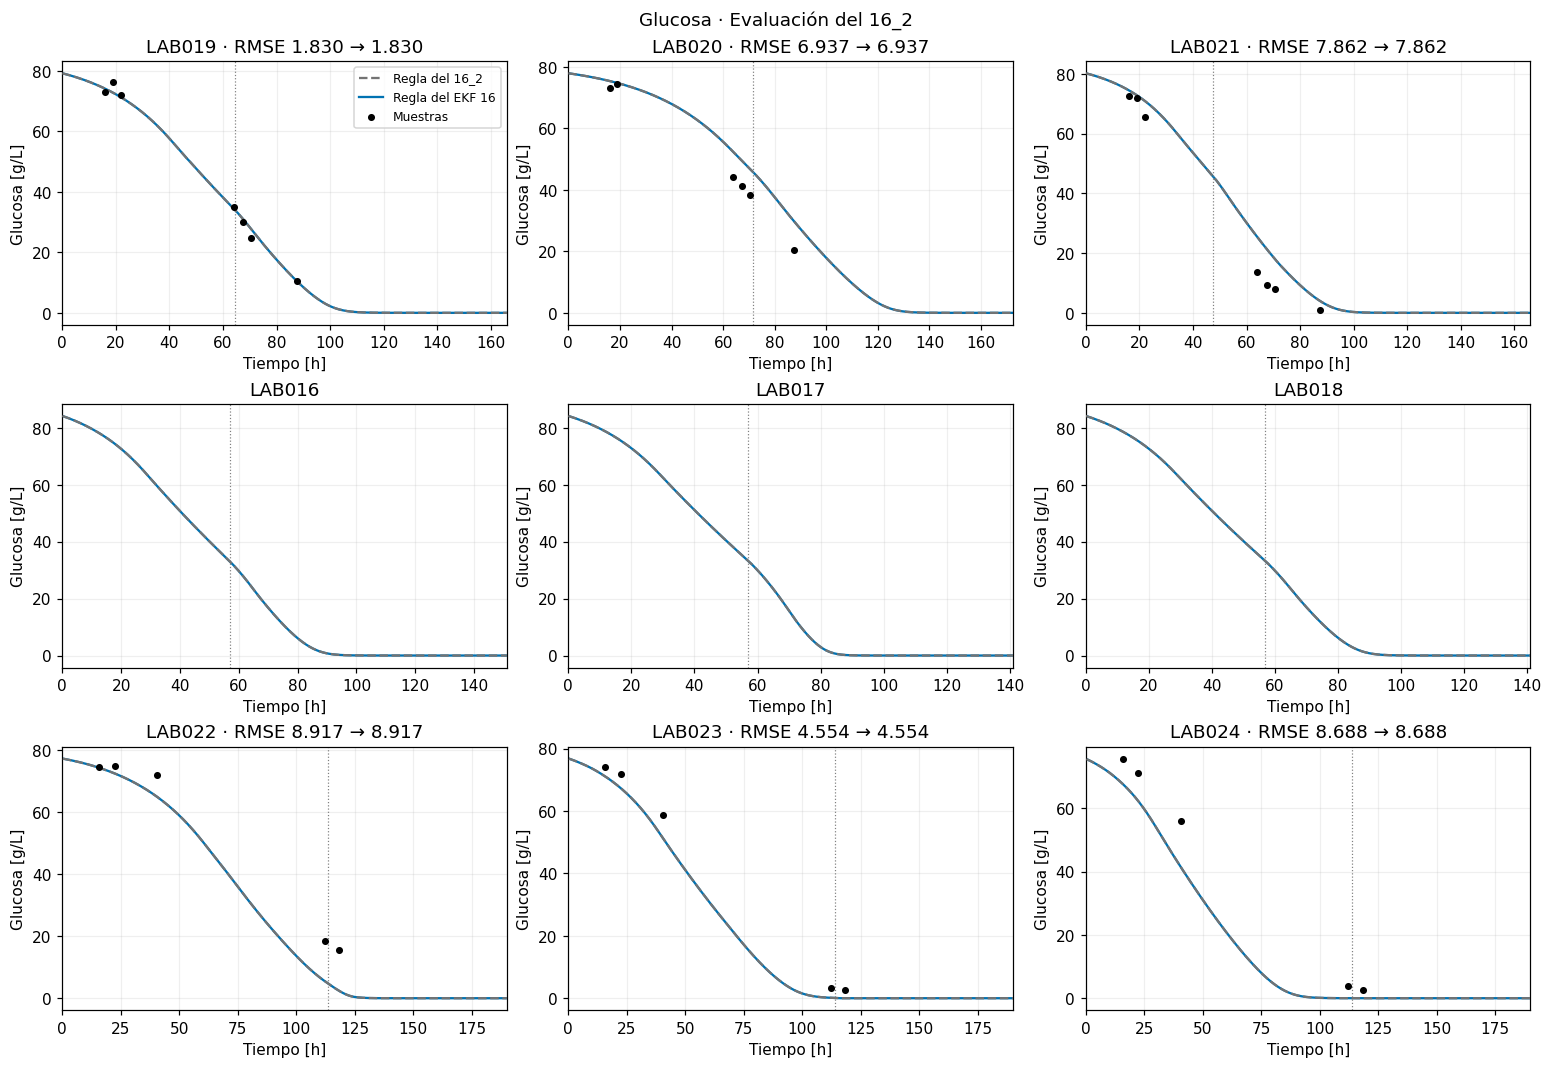

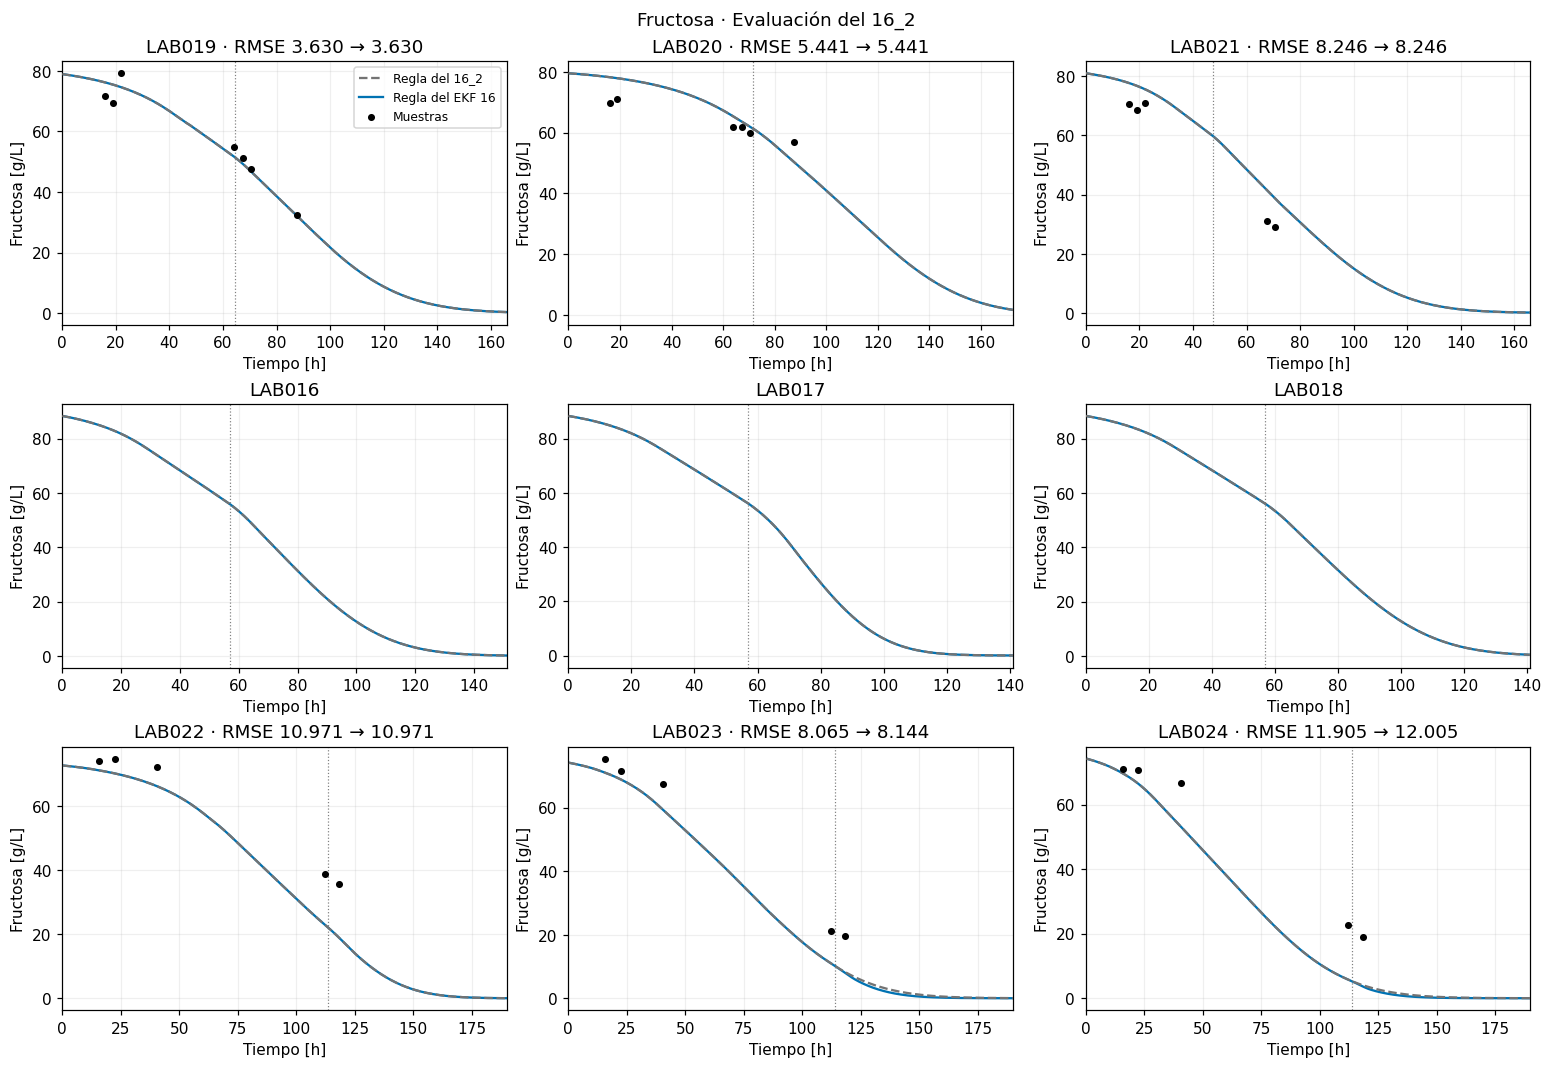

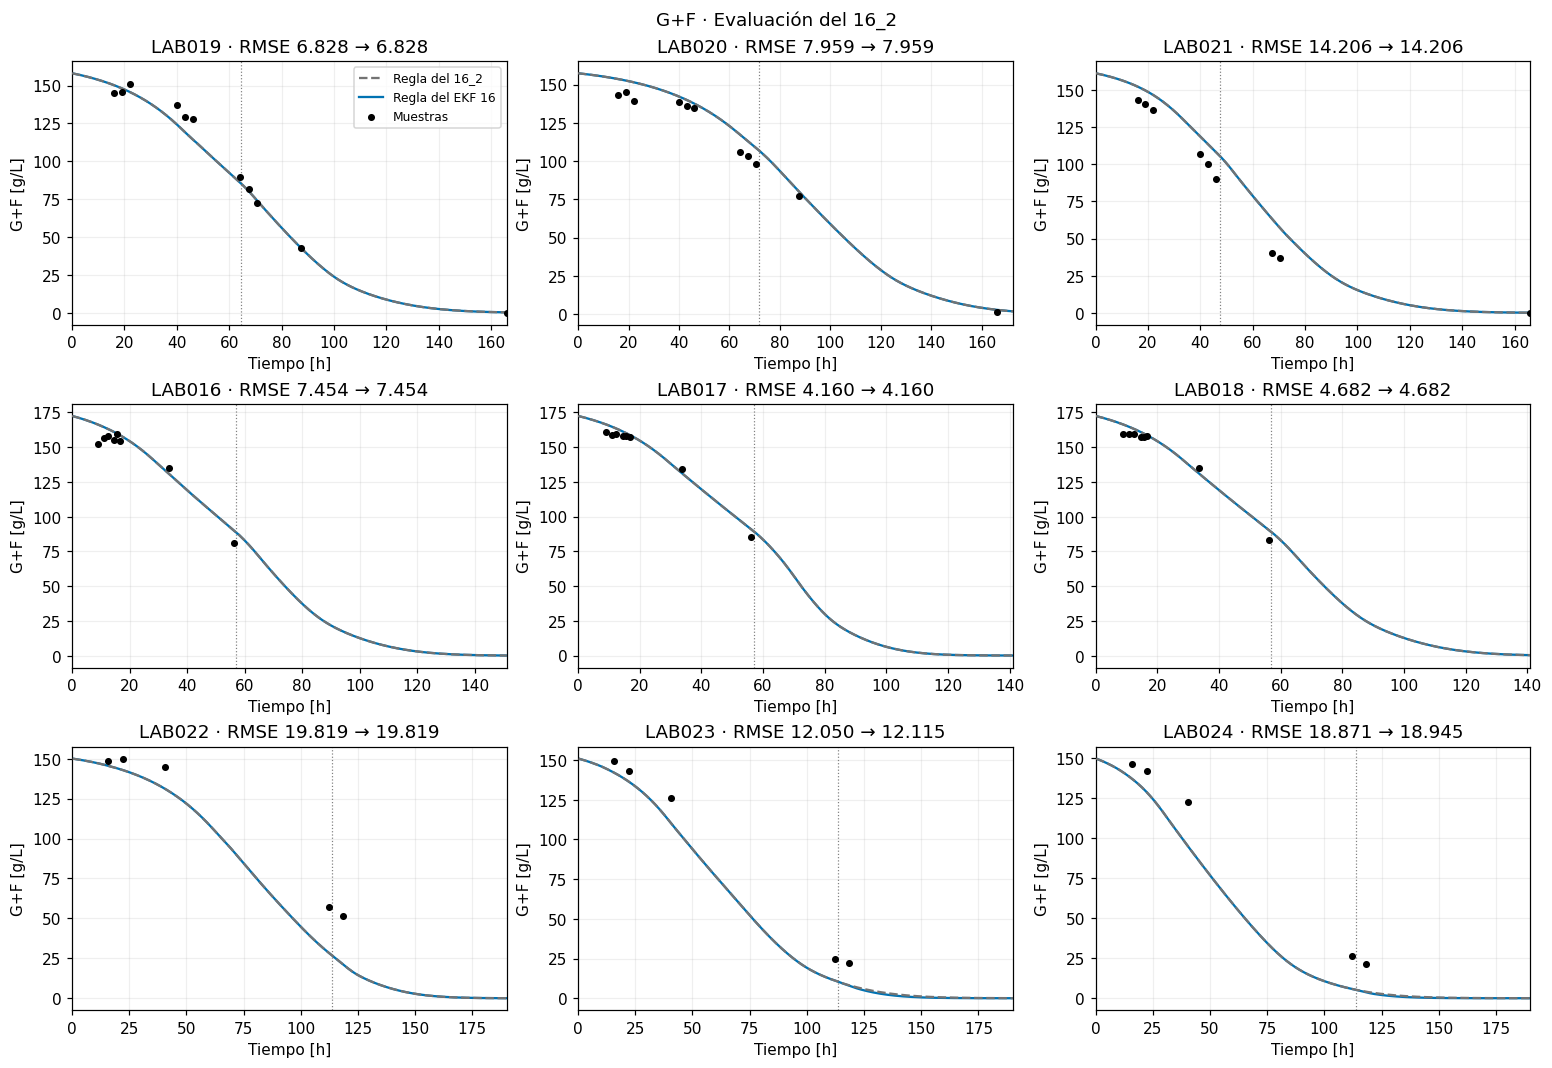

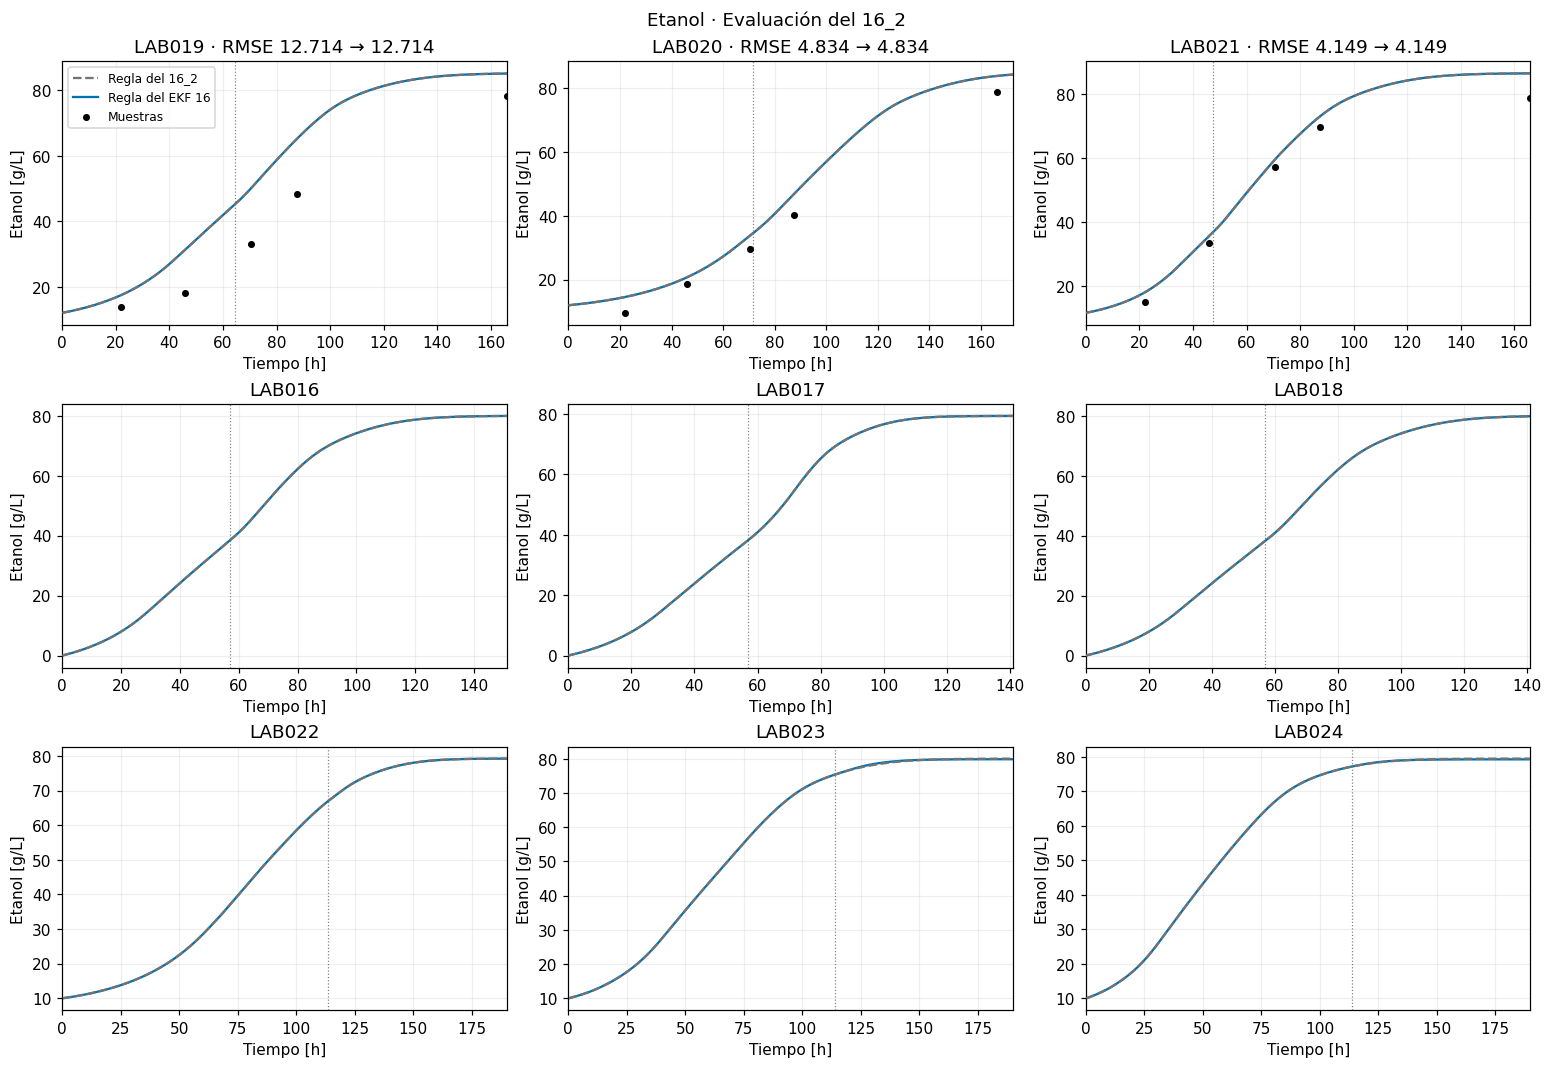

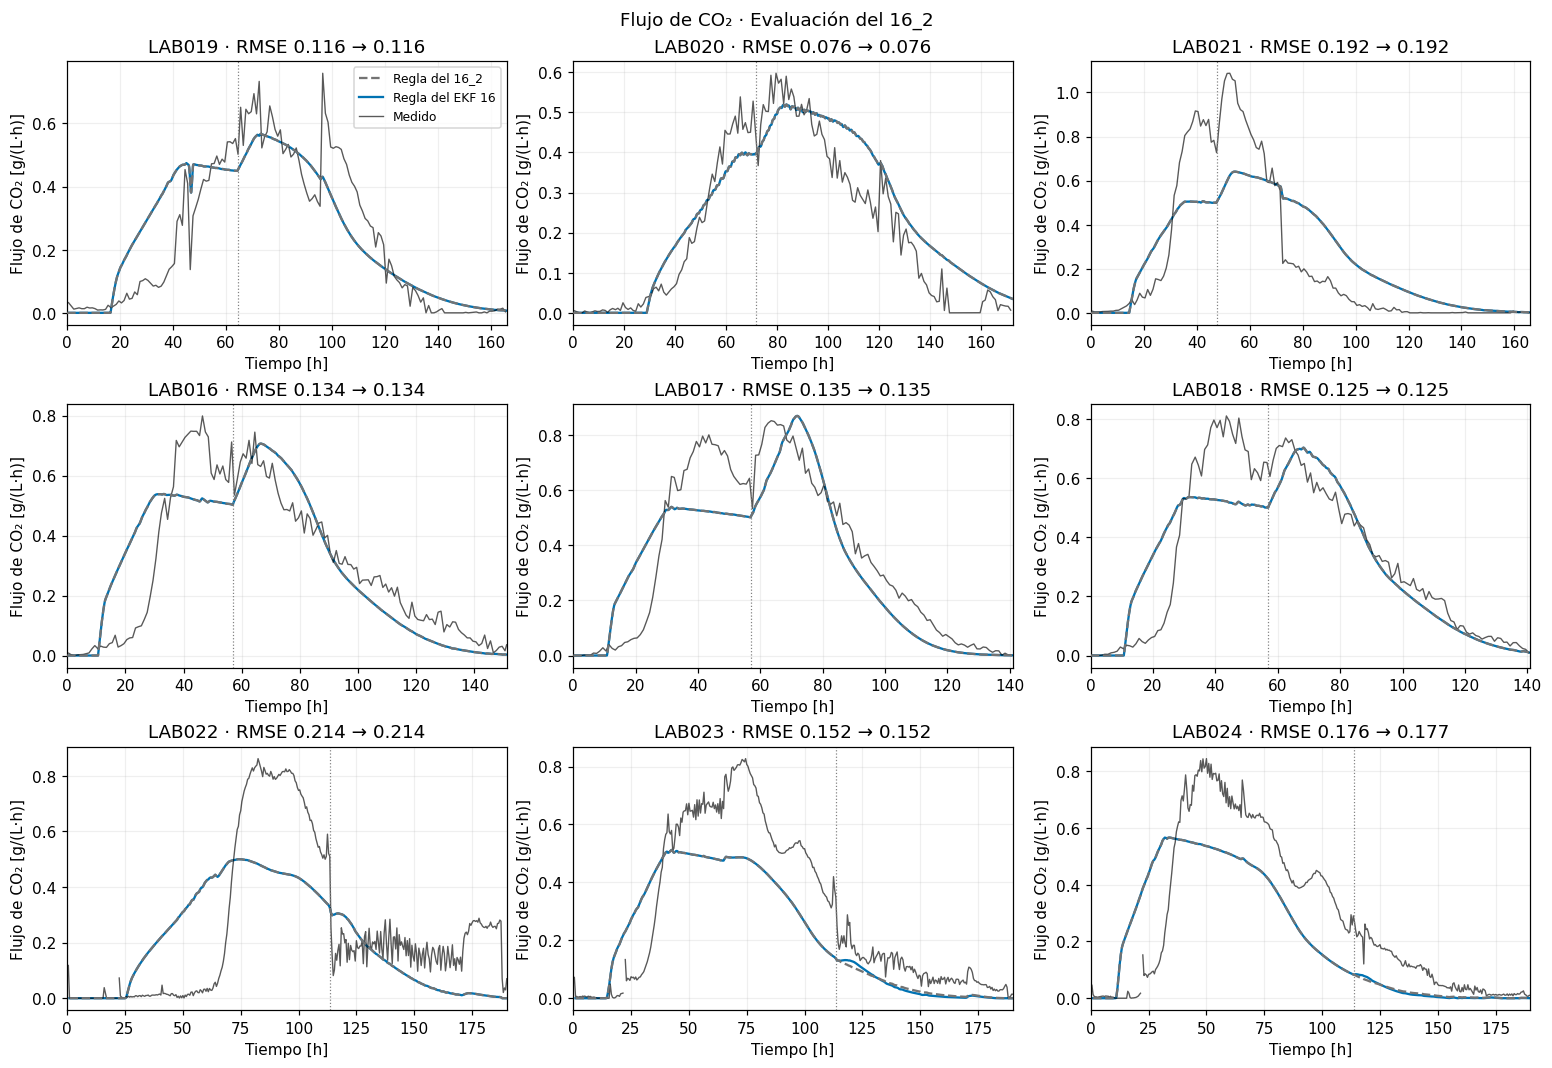

In [4]:
styles = {BASE: dict(color="#737373", linestyle="--", zorder=3),
          AVAILABLE: dict(color="#0072B2", zorder=2)}
for group, labs in (("Calibración química", tuple(training)),
                    ("Evaluación del 16_2", (*historical, *recent))):
    for state, (title, unit, _) in VARS.items():
        if state == "CO2" and group == "Calibración química":
            continue
        fig, axes = plt.subplots(len(labs) // 3, 3, figsize=(14, 3.3 * len(labs) // 3 + .6),
                                 layout="constrained")
        for ax, lab in zip(axes.flat, labs):
            for label in LABELS:
                frame = predicted(label, lab, state, plot=True)
                ax.plot(frame.index, frame.values, label=label, **styles[label])
            obs = samples[lab, state]
            if state == "CO2":
                if lab in recent:
                    obs = setup["holdout_flow"][lab]
                ax.plot(obs.index, obs.values, color="black", alpha=.65, lw=.9, label="Medido")
            else:
                ax.scatter(obs.index, obs.values, c="black", s=13, zorder=5, label="Muestras")
            for pulse, _ in batches[lab].pulses["N"]:
                ax.axvline(pulse, c="gray", ls=":", lw=.8)
            subtitle = lab
            if (lab, state) in rmse.index:
                old, new = rmse.loc[(lab, state), list(LABELS)]
                subtitle += f" · RMSE {old:.3f} → {new:.3f}"
            horizon = v.horizons[lab] if lab in historical else batches[lab].time[-1]
            ax.set(title=subtitle, xlabel="Tiempo [h]", ylabel=f"{title} [{unit}]", xlim=(0, horizon))
            ax.grid(alpha=.2)
        axes.flat[0].legend(fontsize=8)
        fig.suptitle(f"{title} · {group}")
        plt.show()

## Identificabilidad práctica de las constantes de inhibición y las tasas máximas

Se estudian \(K_{IG0}\), \(K_{IE0}\), \(\beta_{G0}\) y \(\beta_{F0}\) con los ocho parámetros libres y las mismas 283 observaciones ponderadas de LAB004–009 del ajuste actual. Se utiliza la regla de crecimiento por azúcar disponible. Las concentraciones iniciales, los pulsos, las temperaturas, las constantes fijas y las cotas se conservan.

Se analizan las sensibilidades respecto de los logaritmos de los parámetros, sus correlaciones locales y los perfiles del objetivo. En cada perfil se fija una constante de inhibición y se reajustan los otros siete parámetros. Esto permite observar cuánto se pueden compensar las tasas máximas y los rendimientos.

Las escalas del ajuste son ponderaciones empíricas y el rendimiento de etanol por fructosa está cerca de una cota. Las correlaciones corresponden a una aproximación lineal local. Los umbrales de aumento del objetivo de 1 % y 5 % se utilizan como referencias comparativas. Los rangos muestreados se presentan con esos umbrales y con las cotas utilizadas. El análisis evalúa la identificabilidad práctica de este experimento y parametrización.

Referencia metodológica: Raue y colaboradores (2009), *Structural and practical identifiability analysis of partially observed dynamical models by exploiting the profile likelihood*, https://doi.org/10.1093/bioinformatics/btp358.

Para reducir el ruido numérico en las derivadas se utilizan tolerancias de integración más estrictas. Se comprueba el cambio del objetivo respecto de la simulación original. El centro de los perfiles se obtiene refinando el vector guardado para el diagnóstico.

In [5]:
from scipy.optimize import least_squares

ident_config = json.loads((ROOT / "configs/models/without_transporters/calibration.json").read_text())
ident_names = [name for name in ident_config["bounds"] if name not in ("aN", "KNa", "Kn0", "Kd0")]
assert len(ident_names) == 8
ident_bounds = np.array([ident_config["bounds"][name] for name in ident_names])
ident_low, ident_high = np.log(ident_bounds).T
ident_support = setup["support"]
ident_count = sum(int(mask.sum()) for _, _, mask in ident_support)
assert ident_count == 283

ident_context = {**setup, "solve_ivp": integrate_sugar_events}
ident_chemistry = simulate_source.replace(old_guard, new_guard)
assert ident_chemistry.count("rtol=2e-6,atol=2e-8") == 1
ident_chemistry = ident_chemistry.replace("rtol=2e-6,atol=2e-8", "rtol=2e-8,atol=2e-10")
exec(compile(ident_chemistry, "16_3_identifiability", "exec"), ident_context)
ident_simulate = ident_context["simulate"]
ident_rejections = 0

def ident_residual(log_values):
    global ident_rejections
    parameters = {**theta, **dict(zip(ident_names, np.exp(log_values)))}
    try:
        predictions = {lab: ident_simulate(batch, parameters) for lab, batch in training.items()}
        residuals = np.concatenate([
            (predictions[batch.batch][state].to_numpy()[mask] - batch.observations[state][mask])
            / setup["sigma"](state, batch.observations[state][mask])
            for batch, state, mask in ident_support
        ])
        if not np.isfinite(residuals).all():
            raise FloatingPointError("Residuos no finitos")
        return residuals
    except (RuntimeError, ValueError, FloatingPointError):
        ident_rejections += 1
        return np.full(ident_count, 1e4)

ident_saved_log = np.log([theta[name] for name in ident_names])
ident_saved_residual = ident_residual(ident_saved_log)
ident_saved_mse = float(np.mean(ident_saved_residual**2))
print("Objetivo guardado:", weighted[AVAILABLE])
print("Objetivo con integración más precisa:", ident_saved_mse)
print("Diferencia relativa [%]:", 100 * (ident_saved_mse / weighted[AVAILABLE] - 1))
np.testing.assert_allclose(ident_saved_mse, weighted[AVAILABLE], rtol=2e-4)
ident_fit = least_squares(ident_residual, ident_saved_log, bounds=(ident_low, ident_high),
                          diff_step=1e-3, max_nfev=100, ftol=1e-7, xtol=1e-7, gtol=1e-6)
assert ident_fit.success, ident_fit.message
ident_center = ident_fit.x.copy() if ident_fit.fun @ ident_fit.fun <= ident_saved_residual @ ident_saved_residual else ident_saved_log.copy()
ident_center_residual = ident_residual(ident_center)
ident_center_mse = float(np.mean(ident_center_residual**2))
ident_center_theta = {**theta, **dict(zip(ident_names, np.exp(ident_center)))}
display(pd.DataFrame({"Ajuste actual": [theta[name] for name in ident_names],
                      "Centro del diagnóstico": np.exp(ident_center),
                      "Cambio %": 100 * (np.exp(ident_center) / np.exp(ident_saved_log) - 1)}, index=ident_names))
print("Centro del diagnóstico:", ident_center_mse, "convergencia", ident_fit.success)

Objetivo guardado: 4.715502281177189
Objetivo con integración más precisa: 4.715512961193721
Diferencia relativa [%]: 0.0002264873579793658


,Ajuste actual,Centro del diagnóstico,Cambio %
mu0,0.086722,0.086731,0.010679
betaG0,0.428291,0.426822,-0.342889
betaF0,0.593521,0.591737,-0.300588
Kig0,80.490799,81.056308,0.702576
Kie0,168.120412,170.075413,1.162858
Yxn,5.272368,5.272701,0.006318
Yeg,0.459547,0.458770,-0.168939
Yef,0.510598,0.511395,0.156224


Centro del diagnóstico: 4.715500847324523 convergencia True


## Sensibilidades y correlaciones locales

La matriz \(J\) contiene las derivadas de los residuos ponderados respecto de \(\log\theta\). Se calculan diferencias centrales con pasos de 0,001 y 0,0005. La norma de cada columna mide la sensibilidad a cambios relativos del parámetro. La descomposición en valores singulares muestra las combinaciones menos observables.

La matriz local de covarianza se aproxima mediante \([\sum r_i^2/(283-8)](J^TJ)^{-1}\). Sus correlaciones consideran simultáneamente los ocho parámetros. La pendiente local \(C_{\log\beta,\log K}/C_{\log K,\log K}\) estima la variación porcentual de una tasa que acompaña a una variación de 1 % de la constante de inhibición al reajustar los demás parámetros.

,Valor actual,Norma de sensibilidad,Diferencia de derivadas %,Desviación local de logaritmo
mu0,0.086722,115.142620,0.015540,0.024249
betaG0,0.428291,95.404508,0.012790,0.213530
betaF0,0.593521,83.148633,0.012270,0.284757
Kig0,80.490799,25.764034,0.039682,0.408060
Kie0,168.120412,27.344079,0.044063,0.597209
Yxn,5.272368,116.770869,0.025060,0.028519
Yeg,0.459547,110.872699,0.018885,0.190487
Yef,0.510598,100.891568,0.013770,0.194933


,mu0,betaG0,betaF0,Kig0,Kie0,Yxn,Yeg,Yef
mu0,1.0000,-0.0707,-0.0245,-0.1060,0.0245,0.3238,0.0238,-0.0157
betaG0,-0.0707,1.0000,-0.2075,-0.4202,-0.4583,0.0118,0.8709,-0.8578
betaF0,-0.0245,-0.2075,1.0000,-0.5933,-0.7090,0.0136,-0.6149,0.6257
Kig0,-0.1060,-0.4202,-0.5933,1.0000,0.6290,-0.0572,-0.1527,0.1513
Kie0,0.0245,-0.4583,-0.7090,0.6290,1.0000,-0.1556,0.0103,-0.0172
Yxn,0.3238,0.0118,0.0136,-0.0572,-0.1556,1.0000,0.0287,-0.0078
Yeg,0.0238,0.8709,-0.6149,-0.1527,0.0103,0.0287,1.0000,-0.9852
Yef,-0.0157,-0.8578,0.6257,0.1513,-0.0172,-0.0078,-0.9852,1.0000


Valores singulares: [185.49204489 113.37060501 102.26084351  81.95642749  47.47615305
   7.78126943   5.80578729   3.12294898]
Número de condición: 59.39643776994899
Rango numérico: 8 de 8


mu0       0.000180
betaG0    0.134164
betaF0    0.310388
Kig0     -0.459475
Kie0     -0.821271
Yxn       0.005083
Yeg      -0.002771
Yef       0.004796
Name: Combinación de menor sensibilidad en logaritmos, dtype: float64

,Constante,Tasa máxima,Correlación local,Cambio de tasa % por 1 % de constante
0,Kig0,betaG0,-0.4202,-0.2199
1,Kig0,betaF0,-0.5933,-0.4140
2,Kie0,betaG0,-0.4583,-0.1639
3,Kie0,betaF0,-0.7090,-0.3381


Constante Tasa máxima  Correlación local  Cambio de tasa % por 1 % de constante
     Kig0      betaG0            -0.4202                                -0.2199
     Kig0      betaF0            -0.5933                                -0.4140
     Kie0      betaG0            -0.4583                                -0.1639
     Kie0      betaF0            -0.7090                                -0.3381


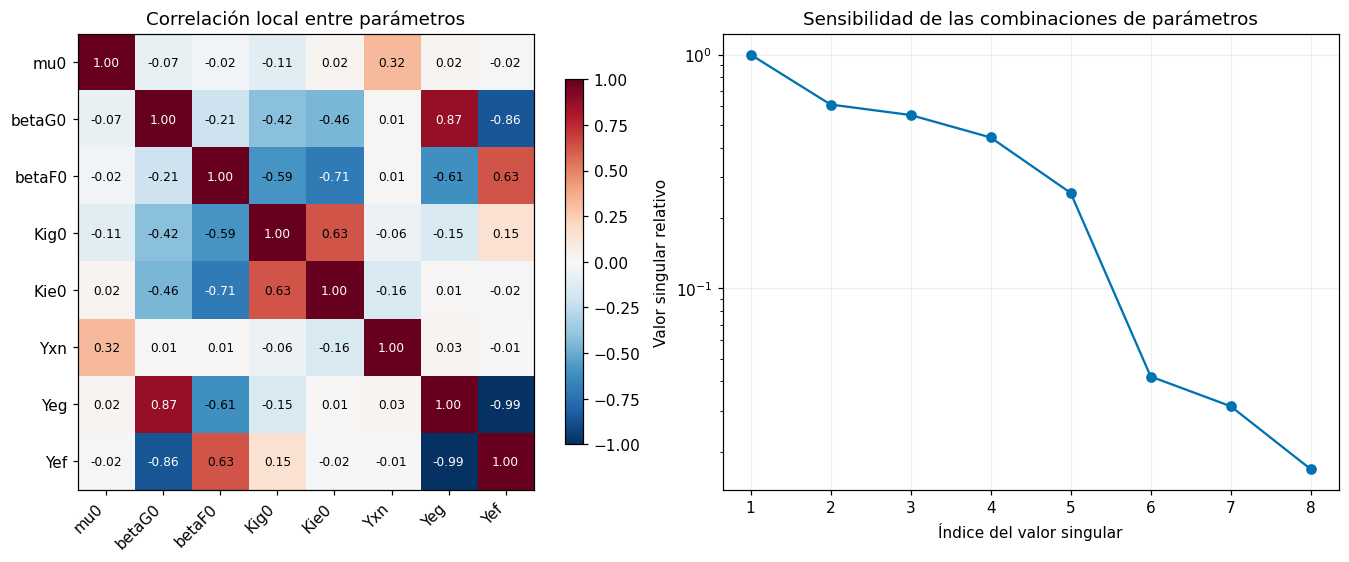

In [6]:
def ident_jacobian(step):
    columns = []
    for index, name in enumerate(ident_names):
        delta = np.zeros(len(ident_names))
        delta[index] = step
        columns.append((ident_residual(ident_saved_log + delta) - ident_residual(ident_saved_log - delta)) / (2 * step))
    return np.column_stack(columns)

ident_jac_coarse = ident_jacobian(1e-3)
ident_jac = ident_jacobian(5e-4)
ident_norms = np.linalg.norm(ident_jac, axis=0)
ident_step_error = np.linalg.norm(ident_jac - ident_jac_coarse, axis=0) / ident_norms
ident_u, ident_singular, ident_vt = np.linalg.svd(ident_jac, full_matrices=False)
ident_rank = int(np.sum(ident_singular > ident_singular[0] * max(ident_jac.shape) * np.finfo(float).eps))
assert ident_rank == len(ident_names), "La matriz local pierde rango numérico"
ident_variance = float(ident_saved_residual @ ident_saved_residual / (ident_count - len(ident_names)))
ident_covariance = (ident_vt.T * (ident_variance / ident_singular**2)) @ ident_vt
ident_standard = np.sqrt(np.diag(ident_covariance))
ident_correlation = ident_covariance / np.outer(ident_standard, ident_standard)
ident_corr_table = pd.DataFrame(ident_correlation, index=ident_names, columns=ident_names)
ident_sensitivity = pd.DataFrame({
    "Valor actual": [theta[name] for name in ident_names],
    "Norma de sensibilidad": ident_norms,
    "Diferencia de derivadas %": 100 * ident_step_error,
    "Desviación local de logaritmo": ident_standard,
}, index=ident_names)
display(ident_sensitivity.round(6))
display(ident_corr_table.round(4))
print("Valores singulares:", ident_singular)
print("Número de condición:", ident_singular[0] / ident_singular[-1])
print("Rango numérico:", ident_rank, "de", len(ident_names))
display(pd.Series(ident_vt[-1], index=ident_names, name="Combinación de menor sensibilidad en logaritmos"))

ident_pairs = []
for inhibition in ("Kig0", "Kie0"):
    k = ident_names.index(inhibition)
    for rate in ("betaG0", "betaF0"):
        b = ident_names.index(rate)
        ident_pairs.append({"Constante": inhibition, "Tasa máxima": rate,
                            "Correlación local": ident_correlation[k, b],
                            "Cambio de tasa % por 1 % de constante": ident_covariance[b, k] / ident_covariance[k, k]})
ident_pairs = pd.DataFrame(ident_pairs)
display(ident_pairs.round(4))
print(ident_pairs.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
heat = axes[0].imshow(ident_correlation, vmin=-1, vmax=1, cmap="RdBu_r")
axes[0].set_xticks(range(len(ident_names)), ident_names, rotation=45, ha="right")
axes[0].set_yticks(range(len(ident_names)), ident_names)
for row in range(len(ident_names)):
    for column in range(len(ident_names)):
        value = ident_correlation[row, column]
        axes[0].text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=8,
                     color="white" if abs(value) > .65 else "black")
axes[0].set_title("Correlación local entre parámetros")
fig.colorbar(heat, ax=axes[0], shrink=.8)
axes[1].semilogy(range(1, len(ident_names) + 1), ident_singular / ident_singular[0], "o-", color="#0072B2")
axes[1].set(xlabel="Índice del valor singular", ylabel="Valor singular relativo", title="Sensibilidad de las combinaciones de parámetros")
axes[1].grid(alpha=.2)
plt.show()

## Perfiles de las constantes de inhibición

Se recorren valores positivos que incluyen las cotas de 5 y 1000 g/L, el centro del diagnóstico, fracciones y múltiplos de ese centro y 40 g/L. Para cada valor se muestran dos objetivos, uno con los demás parámetros conservados en el centro y otro tras reajustar los siete restantes.

El recorrido comienza en el centro y avanza por separado hacia valores menores y mayores, usando como inicio el último ajuste de cada dirección. Se repite desde el centro cuando el optimizador no converge o supera el objetivo del vector sin reajuste. Cada fila incluye la convergencia y los parámetros que alcanzan las proximidades de una cota. Los perfiles son aproximaciones numéricas locales dentro del intervalo explorado.

En estos perfiles se mantiene un único valor de \(K_{IG0}\) común a los seis lotes, como en 16_3. El 16_4 utiliza la regla \(S_0/4\) por lote, por lo que sus resultados corresponden a otra parametrización.

In [7]:
ident_profile_rows = []
ident_profile_vectors = {}
for inhibition in ("Kig0", "Kie0"):
    fixed_index = ident_names.index(inhibition)
    free_indices = np.array([i for i in range(len(ident_names)) if i != fixed_index])
    center_value = float(np.exp(ident_center[fixed_index]))
    values = np.unique(np.clip(np.r_[5., 40., center_value * np.array([.25, .5, 1., 2., 4.]), 1000.], 5., 1000.))
    directions = (sorted(values[values < center_value], reverse=True), sorted(values[values > center_value]))
    def add_profile(value, solution, cost, fixed_cost, success, evaluations, message):
        physical = dict(zip(ident_names, np.exp(solution)))
        near = [name for i, name in enumerate(ident_names) if i != fixed_index
                and min(abs(solution[i] - ident_low[i]), abs(ident_high[i] - solution[i])) < .02]
        ident_profile_vectors[inhibition, value] = solution.copy()
        ident_profile_rows.append({"Constante": inhibition, "Valor fijo": value,
            "MSE sin reajuste": fixed_cost, "MSE perfil": cost,
            "Convergencia": success, "Evaluaciones": evaluations, "Mensaje": str(message),
            "Cerca de cota": ", ".join(near), **physical})
    add_profile(center_value, ident_center, ident_center_mse, ident_center_mse, True, 0, "Centro")
    for direction in directions:
        warm = ident_center.copy()
        for value in direction:
            log_fixed = float(np.log(value))
            def expand(free):
                full = ident_center.copy()
                full[free_indices] = free
                full[fixed_index] = log_fixed
                return full
            def objective(free):
                return ident_residual(expand(free))
            fixed_vector = ident_center.copy()
            fixed_vector[fixed_index] = log_fixed
            fixed_cost = float(np.mean(ident_residual(fixed_vector)**2))
            solution = least_squares(objective, np.clip(warm[free_indices], ident_low[free_indices]+1e-10, ident_high[free_indices]-1e-10),
                bounds=(ident_low[free_indices], ident_high[free_indices]), diff_step=1e-3,
                max_nfev=100, ftol=2e-6, xtol=2e-6, gtol=1e-5)
            if not solution.success or np.mean(solution.fun**2) > fixed_cost * (1 + 1e-6):
                retry = least_squares(objective, np.clip(ident_center[free_indices], ident_low[free_indices]+1e-10, ident_high[free_indices]-1e-10),
                    bounds=(ident_low[free_indices], ident_high[free_indices]), diff_step=1e-3,
                    max_nfev=180, ftol=2e-6, xtol=2e-6, gtol=1e-5)
                if retry.success and (not solution.success or retry.fun @ retry.fun < solution.fun @ solution.fun):
                    solution = retry
            warm = expand(solution.x)
            cost = float(np.mean(solution.fun**2))
            assert cost <= fixed_cost * (1 + 1e-4), "El perfil supera al vector factible sin reajuste"
            add_profile(value, warm, cost, fixed_cost, solution.success, solution.nfev, solution.message)
            print(inhibition, "fijo", round(value, 5), "MSE", round(cost, 7),
                  "convergencia", solution.success, "nfev", solution.nfev, flush=True)
ident_profiles = pd.DataFrame(ident_profile_rows).sort_values(["Constante", "Valor fijo"]).reset_index(drop=True)
ident_best_mse = min(ident_center_mse, ident_profiles["MSE perfil"].min())
ident_profiles["Aumento del objetivo %"] = 100 * (ident_profiles["MSE perfil"] / ident_best_mse - 1)
ident_profiles["Aumento sin reajuste %"] = 100 * (ident_profiles["MSE sin reajuste"] / ident_best_mse - 1)
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(ident_profiles[["Constante", "Valor fijo", "MSE perfil", "Aumento del objetivo %",
                           "Convergencia", "betaG0", "betaF0", "Yef", "Cerca de cota"]].round(6))
print("Rechazos de integración:", ident_rejections)
print("Perfiles convergentes:", int(ident_profiles.Convergencia.sum()), "de", len(ident_profiles))

Kig0 fijo 40.52815 MSE 4.7635096 convergencia True nfev 11
Kig0 fijo 40.0 MSE 4.7655786 convergencia True nfev 3
Kig0 fijo 20.26408 MSE 4.9408627 convergencia True nfev 8
Kig0 fijo 5.0 MSE 5.4728346 convergencia True nfev 20
Kig0 fijo 162.11262 MSE 4.7419441 convergencia True nfev 11
Kig0 fijo 324.22523 MSE 4.7872854 convergencia True nfev 11
Kig0 fijo 1000.0 MSE 4.8551076 convergencia True nfev 9
Kie0 fijo 85.03771 MSE 4.7403604 convergencia True nfev 7
Kie0 fijo 42.51885 MSE 4.8523329 convergencia True nfev 7
Kie0 fijo 40.0 MSE 4.8675841 convergencia True nfev 5
Kie0 fijo 5.0 MSE 5.5855585 convergencia True nfev 13
Kie0 fijo 340.15083 MSE 4.7258835 convergencia True nfev 7
Kie0 fijo 680.30165 MSE 4.7403569 convergencia True nfev 6
Kie0 fijo 1000.0 MSE 4.7465702 convergencia True nfev 5


,Constante,Valor fijo,MSE perfil,Aumento del objetivo %,Convergencia,betaG0,betaF0,Yef,Cerca de cota
0,Kie0,5.000000,5.585559,18.451014,True,2.701549,9.283770,0.511400,Yef
1,Kie0,40.000000,4.867584,3.225177,True,0.654256,1.318716,0.511400,Yef
2,Kie0,42.518853,4.852333,2.901750,True,0.636949,1.257552,0.511400,Yef
3,Kie0,85.037707,4.740360,0.527187,True,0.497181,0.803848,0.511398,Yef
4,Kie0,170.075413,4.715501,0.000000,True,0.426822,0.591737,0.511395,Yef
5,Kie0,340.150826,4.725884,0.220182,True,0.391946,0.492042,0.511399,Yef
6,Kie0,680.301653,4.740357,0.527113,True,0.374421,0.442737,0.511400,Yef
7,Kie0,1000.000000,4.746570,0.658878,True,0.368936,0.427558,0.511400,Yef
8,Kig0,5.000000,5.472835,16.060516,True,0.738502,6.303726,0.511400,Yef
9,Kig0,20.264077,4.940863,4.779171,True,0.594723,1.545671,0.497194,


Rechazos de integración: 0
Perfiles convergentes: 16 de 16


## Compensación observada y estabilidad del objetivo

Se muestran los perfiles y las tasas máximas elegidas al reajustar. La zona sombreada de las tasas corresponde al rango de valores muestreados con aumento del objetivo de hasta 5 %. Se incluyen las curvas sin reajuste para medir la reducción del deterioro que se obtiene al permitir la compensación.

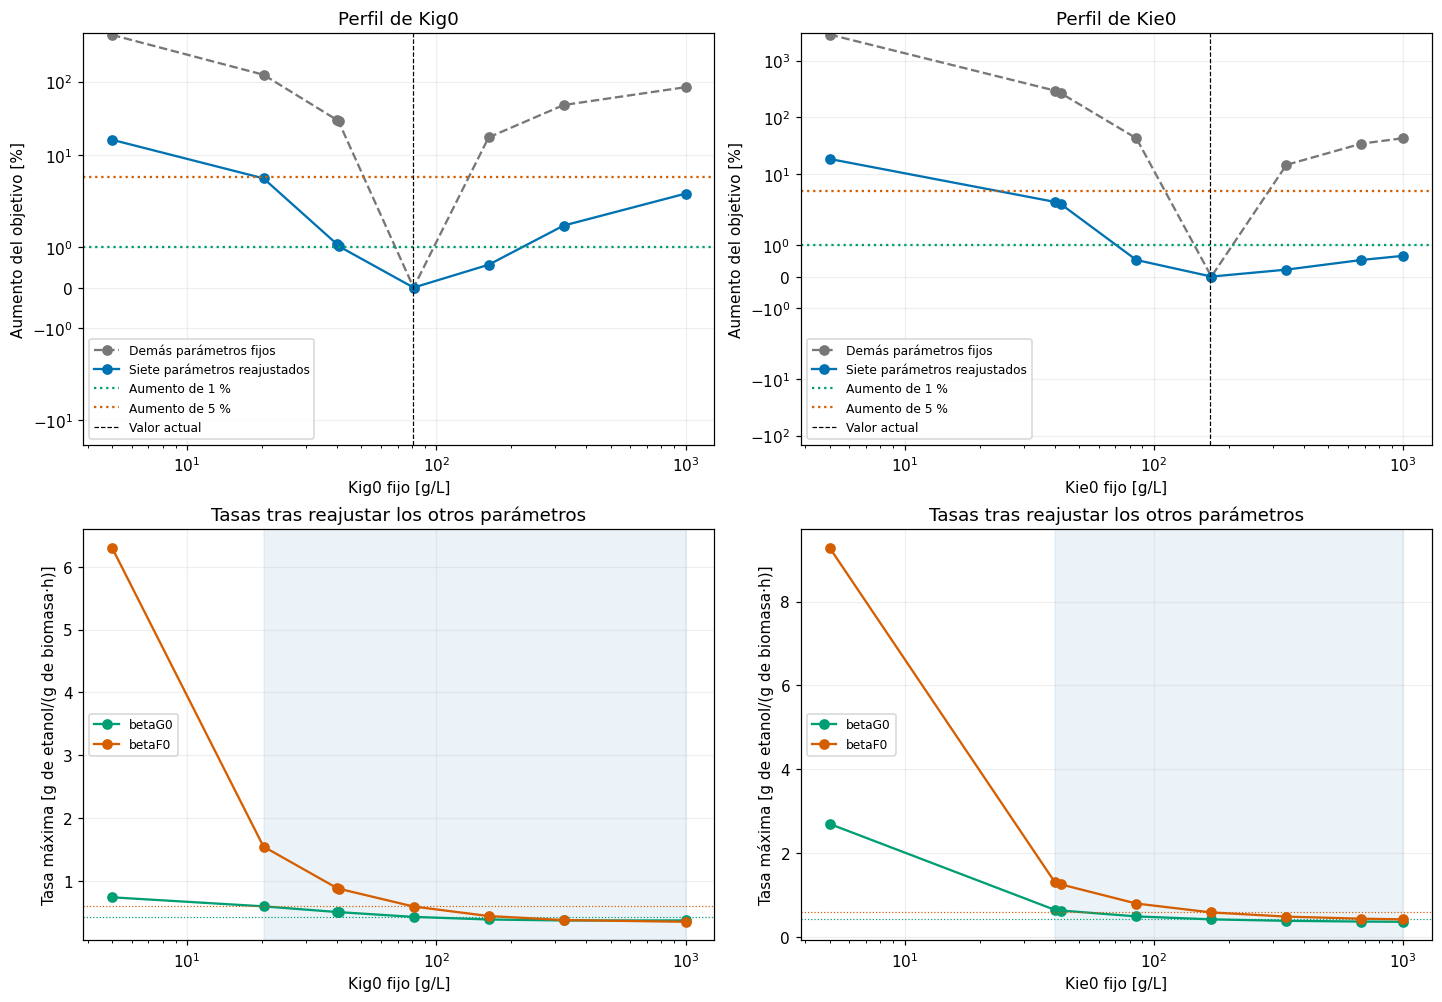

,Constante,Umbral de aumento %,Menor valor muestreado,Mayor valor muestreado,Número de puntos,Alcanza una cota explorada,Menor betaG0,Mayor betaG0,Menor betaF0,Mayor betaF0
0,Kig0,1.0,81.056308,162.112615,2,False,0.385733,0.426822,0.440586,0.591737
1,Kig0,5.0,20.264077,1000.000000,7,True,0.369877,0.594723,0.348983,1.545671
2,Kie0,1.0,85.037707,1000.000000,5,True,0.368936,0.497181,0.427558,0.803848
3,Kie0,5.0,40.000000,1000.000000,7,True,0.368936,0.654256,0.427558,1.318716


Constante  Umbral de aumento %  Menor valor muestreado  Mayor valor muestreado  Número de puntos  Alcanza una cota explorada  Menor betaG0  Mayor betaG0  Menor betaF0  Mayor betaF0
     Kig0                  1.0               81.056308              162.112615                 2                       False      0.385733      0.426822      0.440586      0.591737
     Kig0                  5.0               20.264077             1000.000000                 7                        True      0.369877      0.594723      0.348983      1.545671
     Kie0                  1.0               85.037707             1000.000000                 5                        True      0.368936      0.497181      0.427558      0.803848
     Kie0                  5.0               40.000000             1000.000000                 7                        True      0.368936      0.654256      0.427558      1.318716


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout="constrained")
for column, inhibition in enumerate(("Kig0", "Kie0")):
    frame = ident_profiles.loc[ident_profiles.Constante.eq(inhibition)]
    valid = frame.Convergencia
    axes[0, column].plot(frame["Valor fijo"], frame["Aumento sin reajuste %"], "o--", color="#777777", label="Demás parámetros fijos")
    axes[0, column].plot(frame.loc[valid, "Valor fijo"], frame.loc[valid, "Aumento del objetivo %"], "o-", color="#0072B2", label="Siete parámetros reajustados")
    axes[0, column].axhline(1, color="#009E73", linestyle=":", label="Aumento de 1 %")
    axes[0, column].axhline(5, color="#D55E00", linestyle=":", label="Aumento de 5 %")
    axes[0, column].axvline(theta[inhibition], color="black", linestyle="--", linewidth=.8, label="Valor actual")
    axes[0, column].set(xscale="log", yscale="symlog", xlabel=f"{inhibition} fijo [g/L]",
                        ylabel="Aumento del objetivo [%]", title=f"Perfil de {inhibition}")
    for rate, color in (("betaG0", "#009E73"), ("betaF0", "#D55E00")):
        axes[1, column].plot(frame.loc[valid, "Valor fijo"], frame.loc[valid, rate], "o-", color=color, label=rate)
        axes[1, column].axhline(theta[rate], color=color, linestyle=":", linewidth=.8)
    accepted = frame.loc[valid & frame["Aumento del objetivo %"].le(5)]
    if len(accepted):
        axes[1, column].axvspan(accepted["Valor fijo"].min(), accepted["Valor fijo"].max(), color="#0072B2", alpha=.08)
    axes[1, column].set(xscale="log", xlabel=f"{inhibition} fijo [g/L]",
                        ylabel="Tasa máxima [g de etanol/(g de biomasa·h)]", title="Tasas tras reajustar los otros parámetros")
    for row in range(2):
        axes[row, column].grid(alpha=.2)
        axes[row, column].legend(fontsize=8)
plt.show()

ident_ranges = []
for inhibition in ("Kig0", "Kie0"):
    frame = ident_profiles.loc[ident_profiles.Constante.eq(inhibition) & ident_profiles.Convergencia]
    for limit in (1., 5.):
        accepted = frame.loc[frame["Aumento del objetivo %"].le(limit)]
        assert len(accepted)
        ident_ranges.append({"Constante": inhibition, "Umbral de aumento %": limit,
            "Menor valor muestreado": accepted["Valor fijo"].min(),
            "Mayor valor muestreado": accepted["Valor fijo"].max(),
            "Número de puntos": len(accepted),
            "Alcanza una cota explorada": bool(accepted["Valor fijo"].le(5.00001).any() or accepted["Valor fijo"].ge(999.999).any()),
            "Menor betaG0": accepted.betaG0.min(), "Mayor betaG0": accepted.betaG0.max(),
            "Menor betaF0": accepted.betaF0.min(), "Mayor betaF0": accepted.betaF0.max()})
ident_ranges = pd.DataFrame(ident_ranges)
with pd.option_context("display.max_columns", None):
    display(ident_ranges.round(6))
print(ident_ranges.round(6).to_string(index=False))

## Lectura del diagnóstico

Las correlaciones y pendientes locales cuantifican la compensación cerca del ajuste actual. Los perfiles permiten evaluar la extensión de esa compensación cuando los parámetros cambian más. Los rangos siguientes describen los puntos explorados que conservan el objetivo dentro del umbral elegido. Su interpretación depende de las cotas, el muestreo y la convergencia registrados.

In [9]:
for row in ident_pairs.to_dict("records"):
    print(f"{row['Constante']} / {row['Tasa máxima']}: correlación {row['Correlación local']:.3f}; "
          f"cambio local de tasa {row['Cambio de tasa % por 1 % de constante']:.3f} % por 1 % de constante.")
for row in ident_ranges.to_dict("records"):
    print(f"{row['Constante']}: con aumento del objetivo de hasta {row['Umbral de aumento %']:.0f} %, "
          f"los puntos aceptados van de {row['Menor valor muestreado']:.3f} a {row['Mayor valor muestreado']:.3f} g/L.")
print("Máxima diferencia relativa entre derivadas [%]:", 100 * ident_step_error.max())
print("Yef actual y cota superior:", theta["Yef"], np.exp(ident_high[ident_names.index("Yef")]))
print("Análisis completado con", ident_count, "observaciones y", len(ident_names), "parámetros libres.")
assert np.array_equal(np.log([theta[name] for name in ident_names]), ident_saved_log)
assert np.isfinite(ident_jac).all() and np.isfinite(ident_correlation).all()
assert ident_profiles.Convergencia.all(), "Revisar las filas de perfil que no convergen"

Kig0 / betaG0: correlación -0.420; cambio local de tasa -0.220 % por 1 % de constante.
Kig0 / betaF0: correlación -0.593; cambio local de tasa -0.414 % por 1 % de constante.
Kie0 / betaG0: correlación -0.458; cambio local de tasa -0.164 % por 1 % de constante.
Kie0 / betaF0: correlación -0.709; cambio local de tasa -0.338 % por 1 % de constante.
Kig0: con aumento del objetivo de hasta 1 %, los puntos aceptados van de 81.056 a 162.113 g/L.
Kig0: con aumento del objetivo de hasta 5 %, los puntos aceptados van de 20.264 a 1000.000 g/L.
Kie0: con aumento del objetivo de hasta 1 %, los puntos aceptados van de 85.038 a 1000.000 g/L.
Kie0: con aumento del objetivo de hasta 5 %, los puntos aceptados van de 40.000 a 1000.000 g/L.
Máxima diferencia relativa entre derivadas [%]: 0.044062689881034574
Yef actual y cota superior: 0.5105977085906764 0.5114
Análisis completado con 283 observaciones y 8 parámetros libres.


## Resumen de la ejecución guardada

La matriz de sensibilidades tiene rango numérico 8 de 8 y un número de condición de 59,4. La diferencia máxima de las derivadas calculadas con los dos pasos es 0,044 %. La combinación de menor sensibilidad está dominada por las dos constantes de inhibición y las tasas máximas de producción de etanol.

Las correlaciones locales de \(K_{IG0}\) con \(\beta_{G0}\) y \(\beta_{F0}\) son −0,420 y −0,593. Las de \(K_{IE0}\) con esas tasas son −0,458 y −0,709. Al aumentar una constante de inhibición, el reajuste local tiende a reducir las tasas máximas. La correlación entre los rendimientos \(Y_{E/G}\) y \(Y_{E/F}\) alcanza −0,985, por lo que también intervienen en la compensación.

| Constante | Valores de la malla con aumento del objetivo de hasta 1 % [g/L] | Valores de la malla con aumento del objetivo de hasta 5 % [g/L] |
|---|---:|---:|
| \(K_{IG0}\) | 81,06–162,11 | 20,26–1000 |
| \(K_{IE0}\) | 85,04–1000 | 40–1000 |

Los 16 puntos de perfil convergen. En el perfil de glucosa, el rango con aumento de hasta 5 % incluye valores de \(\beta_{F0}\) entre 0,349 y 1,546. En el de etanol incluye valores entre 0,428 y 1,319, en g de etanol por g de biomasa y hora. La cercanía de las curvas ajustadas puede coexistir con cambios importantes de estos parámetros.

Estos rangos describen los puntos ensayados y dependen de las cotas, los otros parámetros libres y el umbral comparativo elegido. La exploración alcanza la cota de 1000 g/L y varios ajustes alcanzan la proximidad de la cota de \(Y_{E/F}\). Las correlaciones locales utilizan una aproximación lineal que requiere esa misma cautela cerca de las cotas. Los resultados indican una identificabilidad práctica limitada de las constantes de inhibición con las observaciones de calibración disponibles.

## Evaluación química de los conjuntos de los perfiles en LAB016–024

Se utilizan los conjuntos convergentes de los perfiles cuyo objetivo de calibración aumenta como máximo un 5 %, además del ajuste actual y el centro refinado del diagnóstico. Cada conjunto contiene los ocho parámetros reajustados en LAB004–009; únicamente la constante recorrida se mantiene fija en su perfil. El umbral del 5 % es una referencia comparativa, no un intervalo de confianza. Se conservan las constantes restantes, las temperaturas, las condiciones iniciales y las nutriciones del 16_3. Los parámetros se transfieren a LAB016–024 sin recalibración.

La evaluación principal reúne LAB016–021 y LAB023–024. LAB022 se presenta por separado debido a su comportamiento atípico. No se evalúan biomasa ni dióxido de carbono en esta sección. La biomasa sigue formando parte de los balances internos del modelo, aunque sus mediciones no se utilizan para comparar estos conjuntos.

Se excluyen las muestras que fijan la condición inicial y se conserva el horizonte de evaluación del notebook. Se informa la cobertura por variable y fermentación. El azúcar total de LAB016–018 procede de densidad y se presenta como referencia indirecta, separada de las determinaciones químicas. En LAB022–024, la fructosa procede de la diferencia entre azúcar total y glucosa. Glucosa, fructosa y azúcar total no se suman en un objetivo conjunto porque contienen información relacionada. El error cuadrático medio se resume por variable en sus unidades; la agregación reúne las muestras disponibles y puede dar mayor peso a fermentaciones con más muestras.

La banda de los gráficos muestra el mínimo y el máximo de las predicciones de los conjuntos seleccionados de los perfiles. No es una banda de confianza. La línea azul corresponde al ajuste actual y la línea discontinua al centro refinado. Las tablas permiten identificar qué conjunto produce cada error.

In [13]:
from dataclasses import replace

validation_labs = tuple(f"LAB{i:03}" for i in range(16,25))
validation_main = tuple(lab for lab in validation_labs if lab != "LAB022")
validation_states = ("G", "F", "GF", "N", "E")
validation_accepted = ident_profiles.loc[
    ident_profiles.Convergencia & ident_profiles["Aumento del objetivo %"].le(5.)].copy()
validation_parameters = {"Actual": theta.copy(), "Centro": ident_center_theta.copy()}
validation_origins = [{"Conjunto": "Actual", "Perfil": "Ajuste guardado", "Valor fijo [g/L]": np.nan,
                       "Aumento en calibración [%]": 100*(ident_saved_mse/ident_best_mse-1)},
                      {"Conjunto": "Centro", "Perfil": "Centro refinado", "Valor fijo [g/L]": np.nan,
                       "Aumento en calibración [%]": 100*(ident_center_mse/ident_best_mse-1)}]
for row in validation_accepted.to_dict("records"):
    parameters = {**theta, **{name: float(row[name]) for name in ident_names}}
    if np.allclose([parameters[k] for k in ident_names], [ident_center_theta[k] for k in ident_names],rtol=1e-12,atol=0):
        continue  # Los dos perfiles contienen el mismo centro.
    name = f"{row['Constante']}={row['Valor fijo']:.4f}"
    validation_parameters[name] = parameters
    validation_origins.append({"Conjunto": name,"Perfil": row["Constante"],
        "Valor fijo [g/L]": row["Valor fijo"],"Aumento en calibración [%]": row["Aumento del objetivo %"]})
validation_parameter_table = pd.DataFrame(validation_origins).set_index("Conjunto").join(
    pd.DataFrame(validation_parameters).T[ident_names])
display(validation_parameter_table.round(6))

validation_observations = {(lab,state):observed(lab,state) for lab in validation_labs for state in validation_states}
validation_coverage_rows = []
for (lab,state), obs in validation_observations.items():
    validation_origin = ("Estimado de densidad" if lab in ("LAB016","LAB017","LAB018") and state=="GF"
              else "Derivada de azúcar total menos glucosa" if lab in recent and state=="F"
              else "Determinación química")
    validation_coverage_rows.append({"LAB":lab,"Variable":state,"Origen":validation_origin if len(obs) else "Sin mediciones",
        "n":len(obs),"Primera muestra [h]":obs.index.min() if len(obs) else np.nan,
        "Última muestra [h]":obs.index.max() if len(obs) else np.nan,
        "Grupo":"LAB022 separado" if lab=="LAB022" else "Principal"})
validation_coverage = pd.DataFrame(validation_coverage_rows)
display(validation_coverage.loc[validation_coverage.n.gt(0)].round(3))
print("Cobertura (0 significa sin muestras utilizables):")
display(validation_coverage.pivot(index="LAB",columns="Variable",values="n").reindex(columns=validation_states))

# Usar la dinámica del diagnóstico con sus tolerancias estrictas, sin capa de gas.
# Añadir los horarios de las muestras a la malla para evaluar exactamente en ellos.
validation_batches = {}
for lab in validation_labs:
    batch = batches[lab]
    end = v.horizons[lab] if lab in historical else batch.time[-1]
    sample_times = np.concatenate([obs.index.to_numpy(float) for (key,_),obs in validation_observations.items() if key==lab])
    times = np.unique(np.r_[batch.time[(batch.time>=batch.time[0]) & (batch.time<=end)],sample_times,end])
    validation_batches[lab] = replace(batch,time=times,temperature_c=np.interp(times,batch.time,batch.temperature_c))
validation_curves = {}
for name,parameters in validation_parameters.items():
    validation_curves[name] = {lab: ident_simulate(batch,parameters) for lab,batch in validation_batches.items()}
    for lab,frame in validation_curves[name].items():
        assert np.isfinite(frame.to_numpy()).all() and frame.to_numpy().min()>=0
        np.testing.assert_allclose(frame.iloc[0][list(kin.STATE_NAMES)],kin.initial_vector(validation_batches[lab]),rtol=0,atol=1e-12)
        actual_pulses = [(j["t"],j["after"][1]-j["before"][1]) for j in frame.attrs["pulse_jumps"]]
        expected_pulses = [(t,d) for t,d in batches[lab].pulses["N"] if frame.index[0]<t<=frame.index[-1]]
        np.testing.assert_allclose(actual_pulses,expected_pulses,rtol=0,atol=1e-12)
    print("Simulación química completada:",name,flush=True)

validation_errors = []
for name,curves in validation_curves.items():
    for (lab,state),obs in validation_observations.items():
        if obs.empty: continue
        frame = curves[lab]
        assert obs.index.isin(frame.index).all()
        prediction = frame.loc[obs.index,state].to_numpy()*VARS[state][2]
        assert len(prediction)==len(obs)
        for t,y,pred in zip(obs.index,obs.to_numpy(),prediction):
            validation_errors.append({"Conjunto":name,"LAB":lab,"Variable":state,"Tiempo [h]":t,
                "Medido":y,"Predicho":pred,"Error":pred-y,
                "Grupo":"LAB022 separado" if lab=="LAB022" else "Principal",
                "Origen":"Estimado de densidad" if lab in ("LAB016","LAB017","LAB018") and state=="GF" else "Química"})
validation_errors = pd.DataFrame(validation_errors)
assert not validation_errors.empty
assert "LAB022" not in validation_main
assert set(validation_errors.Variable).issubset(set(validation_states))
print("Conjuntos evaluados:",len(validation_parameters),"; sin reajuste con los datos de evaluación.")
# Registro con precisión completa de los conjuntos realmente transferidos.
print("CONJUNTOS QUÍMICOS EVALUADOS",json.dumps(validation_parameters,ensure_ascii=False))


Cobertura (0 significa sin muestras utilizables):
Simulación química completada: Actual
Simulación química completada: Centro
Simulación química completada: Kie0=40.0000
Simulación química completada: Kie0=42.5189
Simulación química completada: Kie0=85.0377
Simulación química completada: Kie0=340.1508
Simulación química completada: Kie0=680.3017
Simulación química completada: Kie0=1000.0000
Simulación química completada: Kig0=20.2641
Simulación química completada: Kig0=40.0000
Simulación química completada: Kig0=40.5282
Simulación química completada: Kig0=162.1126
Simulación química completada: Kig0=324.2252
Simulación química completada: Kig0=1000.0000
Conjuntos evaluados: 14 ; sin reajuste con los datos de evaluación.
CONJUNTOS QUÍMICOS EVALUADOS {"Actual": {"mu0": 0.08672190419703954, "betaG0": 0.4282909568167695, "betaF0": 0.5935206388397897, "Kn0": 0.008257860224319971, "Kg0": 4.400775419123265, "Kf0": 19.296083508118652, "Kig0": 80.49079852882808, "Kie0": 168.1204117857583, "Kd0"

,Perfil,Valor fijo [g/L],Aumento en calibración [%],mu0,betaG0,betaF0,Kig0,Kie0,Yxn,Yeg,Yef
Conjunto,,,,,,,,,,,
Actual,Ajuste guardado,NaN,0.000257,0.086722,0.428291,0.593521,80.490799,168.120412,5.272368,0.459547,0.510598
Centro,Centro refinado,NaN,0.000000,0.086731,0.426822,0.591737,81.056308,170.075413,5.272701,0.458770,0.511395
Kie0=40.0000,Kie0,40.000000,3.225177,0.086262,0.654256,1.318716,36.375759,40.000000,5.341359,0.459845,0.511400
Kie0=42.5189,Kie0,42.518853,2.901750,0.086290,0.636949,1.257552,37.751453,42.518853,5.337769,0.459943,0.511400
Kie0=85.0377,Kie0,85.037707,0.527187,0.086591,0.497181,0.803848,56.141552,85.037707,5.300114,0.459824,0.511398
Kie0=340.1508,Kie0,340.150826,0.220182,0.086757,0.391946,0.492042,107.053308,340.150826,5.255163,0.457561,0.511399
Kie0=680.3017,Kie0,680.301653,0.527113,0.086743,0.374421,0.442737,130.087596,680.301653,5.246197,0.456248,0.511400
Kie0=1000.0000,Kie0,1000.000000,0.658878,0.086733,0.368936,0.427558,139.491690,1000.000000,5.243102,0.455874,0.511400
Kig0=20.2641,Kig0,20.264077,4.779171,0.087494,0.594723,1.545671,20.264077,51.518160,5.309930,0.474596,0.497194


,LAB,Variable,Origen,n,Primera muestra [h],Última muestra [h],Grupo
2,LAB016,GF,Estimado de densidad,8,8.935,56.185,Principal
7,LAB017,GF,Estimado de densidad,8,8.933,56.183,Principal
12,LAB018,GF,Estimado de densidad,8,8.931,56.181,Principal
15,LAB019,G,Determinación química,7,16.000,87.500,Principal
16,LAB019,F,Determinación química,7,16.000,87.500,Principal
17,LAB019,GF,Determinación química,11,16.000,166.000,Principal
18,LAB019,N,Determinación química,12,16.000,166.000,Principal
19,LAB019,E,Determinación química,5,22.000,166.000,Principal
20,LAB020,G,Determinación química,6,16.000,87.500,Principal
21,LAB020,F,Determinación química,6,16.000,87.500,Principal


Variable,G,F,GF,N,E
LAB,,,,,
LAB016,0,0,8,0,0
LAB017,0,0,8,0,0
LAB018,0,0,8,0,0
LAB019,7,7,11,12,5
LAB020,6,6,11,12,5
LAB021,7,5,9,12,5
LAB022,5,5,5,6,0
LAB023,5,5,5,6,0
LAB024,5,5,5,6,0


## Errores por variable y fermentación

Se presentan por separado el grupo principal, LAB022 y el azúcar estimado de densidad. Cada columna corresponde a un conjunto de parámetros. El error cuadrático medio de cada variable se expresa como su raíz (RMSE): glucosa, fructosa, azúcar total y etanol en g/L; YAN en mg N/L. No se construye una clasificación única mezclando variables o unidades.

En las tablas, G indica glucosa, F fructosa, GF azúcar total, N YAN y E etanol.

In [14]:
validation_metrics_rows = []
for (group,origin,state,name),frame in validation_errors.groupby(["Grupo","Origen","Variable","Conjunto"],sort=False):
    validation_metrics_rows.append({"Grupo":group,"Origen":origin,"Variable":state,"Conjunto":name,
        "n":len(frame),"Fermentaciones":frame.LAB.nunique(),"RMSE":np.sqrt(np.mean(frame.Error**2))})
validation_metrics = pd.DataFrame(validation_metrics_rows)
for (group,origin),frame in validation_metrics.groupby(["Grupo","Origen"],sort=False):
    print(group,"·",origin)
    display(frame.pivot(index="Variable",columns="Conjunto",values="RMSE").reindex(columns=validation_parameters).round(4))
    display(frame.loc[frame.Conjunto.eq("Actual"),["Variable","n","Fermentaciones"]].set_index("Variable"))

validation_per_lab = (validation_errors.assign(Error2=lambda f:f.Error**2)
    .groupby(["LAB","Variable","Conjunto"],sort=False).Error2.mean().pow(.5).unstack("Conjunto")
    .reindex(columns=validation_parameters))
print("RMSE por fermentación y variable · grupo principal")
display(validation_per_lab.loc[list(validation_main)].round(4))
print("RMSE de LAB022 · evaluación separada")
display(validation_per_lab.loc[["LAB022"]].round(4))

validation_spread_rows=[]
for (lab,state),obs in validation_observations.items():
    if obs.empty: continue
    predictions = np.vstack([validation_curves[name][lab].loc[obs.index,state].to_numpy()*VARS[state][2]
                             for name in validation_parameters if name!="Actual"])
    spread=np.ptp(predictions,axis=0)
    actual_rmse=validation_per_lab.loc[(lab,state),"Actual"]
    validation_spread_rows.append({"LAB":lab,"Variable":state,"n":len(obs),
        "Separación media entre perfiles":np.mean(spread),"Separación máxima entre perfiles":np.max(spread),
        "RMSE actual":actual_rmse,"Menor RMSE de perfiles":validation_per_lab.loc[(lab,state)].drop("Actual").min(),
        "Mayor RMSE de perfiles":validation_per_lab.loc[(lab,state)].drop("Actual").max()})
validation_spread=pd.DataFrame(validation_spread_rows)
display(validation_spread.round(4))


Principal · Estimado de densidad
Principal · Química
LAB022 separado · Química
RMSE por fermentación y variable · grupo principal
RMSE de LAB022 · evaluación separada


Conjunto,Actual,Centro,Kie0=40.0000,Kie0=42.5189,Kie0=85.0377,Kie0=340.1508,Kie0=680.3017,Kie0=1000.0000,Kig0=20.2641,Kig0=40.0000,Kig0=40.5282,Kig0=162.1126,Kig0=324.2252,Kig0=1000.0000
Variable,,,,,,,,,,,,,,
GF,5.6208,5.6303,5.7228,5.5712,5.0007,6.2815,6.6836,6.8252,4.9572,5.1381,5.1447,6.1902,6.3576,6.0874


,n,Fermentaciones
Variable,,
GF,24,3


Conjunto,Actual,Centro,Kie0=40.0000,Kie0=42.5189,Kie0=85.0377,Kie0=340.1508,Kie0=680.3017,Kie0=1000.0000,Kig0=20.2641,Kig0=40.0000,Kig0=40.5282,Kig0=162.1126,Kig0=324.2252,Kig0=1000.0000
Variable,,,,,,,,,,,,,,
E,8.2102,8.2097,7.9995,8.0097,8.1005,8.3077,8.3663,8.3918,7.6937,7.9614,7.9685,8.4749,8.6969,8.9001
F,7.7046,7.7027,8.0289,8.0084,7.8287,7.6343,7.5941,7.5827,8.6915,8.1188,8.1086,7.5055,7.4273,7.4133
G,6.3924,6.3874,6.8335,6.8025,6.5366,6.3020,6.2516,6.2351,6.7916,6.5498,6.5469,6.2959,6.2617,6.2836
GF,11.6389,11.6359,11.9663,11.9390,11.7294,11.6045,11.5893,11.5869,12.4152,11.9726,11.9650,11.4630,11.3580,11.2570
N,46.6059,46.6113,45.7018,45.7537,46.2927,46.7617,46.8182,46.8328,46.9389,46.7803,46.7799,46.4629,46.2090,45.7679


,n,Fermentaciones
Variable,,
G,30,5
F,28,5
GF,41,5
N,48,5
E,15,3


Conjunto,Actual,Centro,Kie0=40.0000,Kie0=42.5189,Kie0=85.0377,Kie0=340.1508,Kie0=680.3017,Kie0=1000.0000,Kig0=20.2641,Kig0=40.0000,Kig0=40.5282,Kig0=162.1126,Kig0=324.2252,Kig0=1000.0000
Variable,,,,,,,,,,,,,,
F,10.9716,10.9697,11.6933,11.6583,11.2945,10.7427,10.5999,10.5515,12.1861,11.4542,11.4425,10.6752,10.5895,10.6794
G,8.9169,8.9278,8.3898,8.4084,8.6465,9.1719,9.3394,9.3986,8.1972,8.5822,8.5870,9.2190,9.3719,9.3481
GF,19.8195,19.8287,19.9183,19.9101,19.8475,19.8512,19.8752,19.8852,20.1767,19.9240,19.9184,19.8313,19.8913,19.9493
N,47.5645,47.5704,46.6420,46.6930,47.2387,47.7270,47.7827,47.7969,47.9832,47.7805,47.7799,47.3896,47.1082,46.6498


,n,Fermentaciones
Variable,,
G,5,1
F,5,1
GF,5,1
N,6,1


Conjunto          Actual   Centro  ...  Kig0=324.2252  Kig0=1000.0000
LAB    Variable                    ...                               
LAB016 GF         7.4535   7.4634  ...         8.1932          7.9341
LAB017 GF         4.1594   4.1694  ...         4.9430          4.6428
LAB018 GF         4.6823   4.6919  ...         5.4495          5.1637
LAB019 GF         6.8278   6.8286  ...         7.2594          7.7258
       G          1.8297   1.8247  ...         1.8237          1.8307
       F          3.6299   3.6328  ...         4.3066          4.7430
       N         49.0572  49.0645  ...        48.4753         47.8522
       E         12.7136  12.7137  ...        13.4737         13.7483
LAB020 GF         7.9583   7.9529  ...         7.3637          6.9894
       G          6.9360   6.9305  ...         7.1367          7.2581
       F          5.4409   5.4428  ...         5.8649          6.1905
       N         12.5134  12.5190  ...        12.0876         11.6857
       E          4.8341   4.8351  ...         5.5083          5.8033
LAB021 GF        14.2053  14.2095  ...        14.7655         14.4517
       G          7.8621   7.8564  ...         8.0191          8.0298
       F          8.2459   8.2497  ...         8.4161          8.1797
       N         17.7090  17.7122  ...        17.4547         17.1744
       E          4.1495   4.1450  ...         3.8760          3.8653
LAB023 GF        12.1149  12.1081  ...        11.1271         11.0704
       G          4.5537   4.5497  ...         4.0092          3.9720
       F          8.1442   8.1394  ...         7.3765          7.2795
       N         71.8711  71.8789  ...        71.3379         70.7029
LAB024 GF        18.9449  18.9332  ...        17.5032         17.3735
       G          8.6883   8.6824  ...         7.9609          7.9340
       F         12.0052  11.9969  ...        10.7907         10.5060
       N         80.3607  80.3665  ...        79.9487         79.4734

[26 rows x 14 columns]

Conjunto          Actual   Centro  ...  Kig0=324.2252  Kig0=1000.0000
LAB    Variable                    ...                               
LAB022 GF        19.8195  19.8287  ...        19.8913         19.9493
       G          8.9169   8.9278  ...         9.3719          9.3481
       F         10.9716  10.9697  ...        10.5895         10.6794
       N         47.5645  47.5704  ...        47.1082         46.6498

[4 rows x 14 columns]

,LAB,Variable,n,Separación media entre perfiles,Separación máxima entre perfiles,RMSE actual,Menor RMSE de perfiles,Mayor RMSE de perfiles
0,LAB016,GF,8,6.7654,13.9760,7.4535,6.5137,8.6357
1,LAB017,GF,8,6.6610,13.9183,4.1594,3.6261,5.4593
2,LAB018,GF,8,6.7318,13.8107,4.6823,4.1235,5.9472
3,LAB019,G,7,1.7003,5.1657,1.8297,1.7639,2.5491
4,LAB019,F,7,3.7710,6.2700,3.6299,3.4634,4.7430
5,LAB019,GF,11,3.9491,10.0775,6.8278,6.6015,7.9182
6,LAB019,N,12,1.3219,5.7408,49.0572,47.8310,49.5560
7,LAB019,E,5,2.1549,4.3599,12.7136,11.7363,13.7483
8,LAB020,G,6,1.4308,2.0508,6.9360,6.5538,7.2581
9,LAB020,F,6,4.4168,8.7626,5.4409,5.2616,6.1905


## Predicciones químicas y dispersión entre conjuntos

La banda naranja reúne los conjuntos de los perfiles con aumento del objetivo de hasta 5 %, incluido el centro refinado. Las figuras principales excluyen LAB022. Las líneas verticales indican las nutriciones. Los gráficos conservan los saltos de YAN; las muestras coincidentes con una nutrición se comparan con el valor previo al pulso, como en la calibración. Los paneles sin determinaciones de la variable se identifican explícitamente.

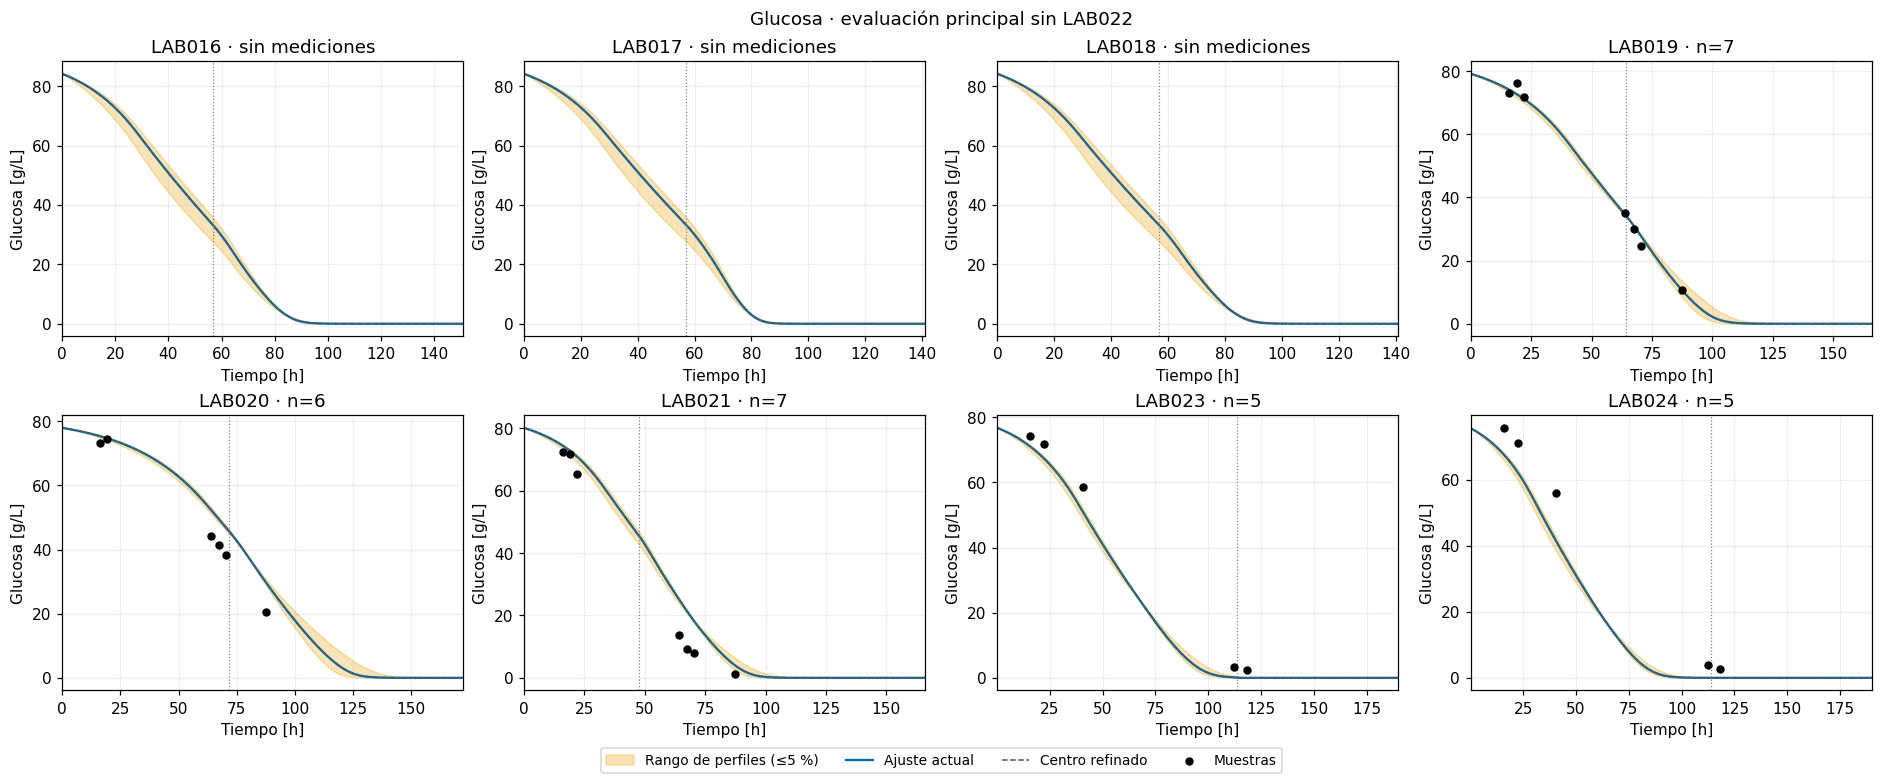

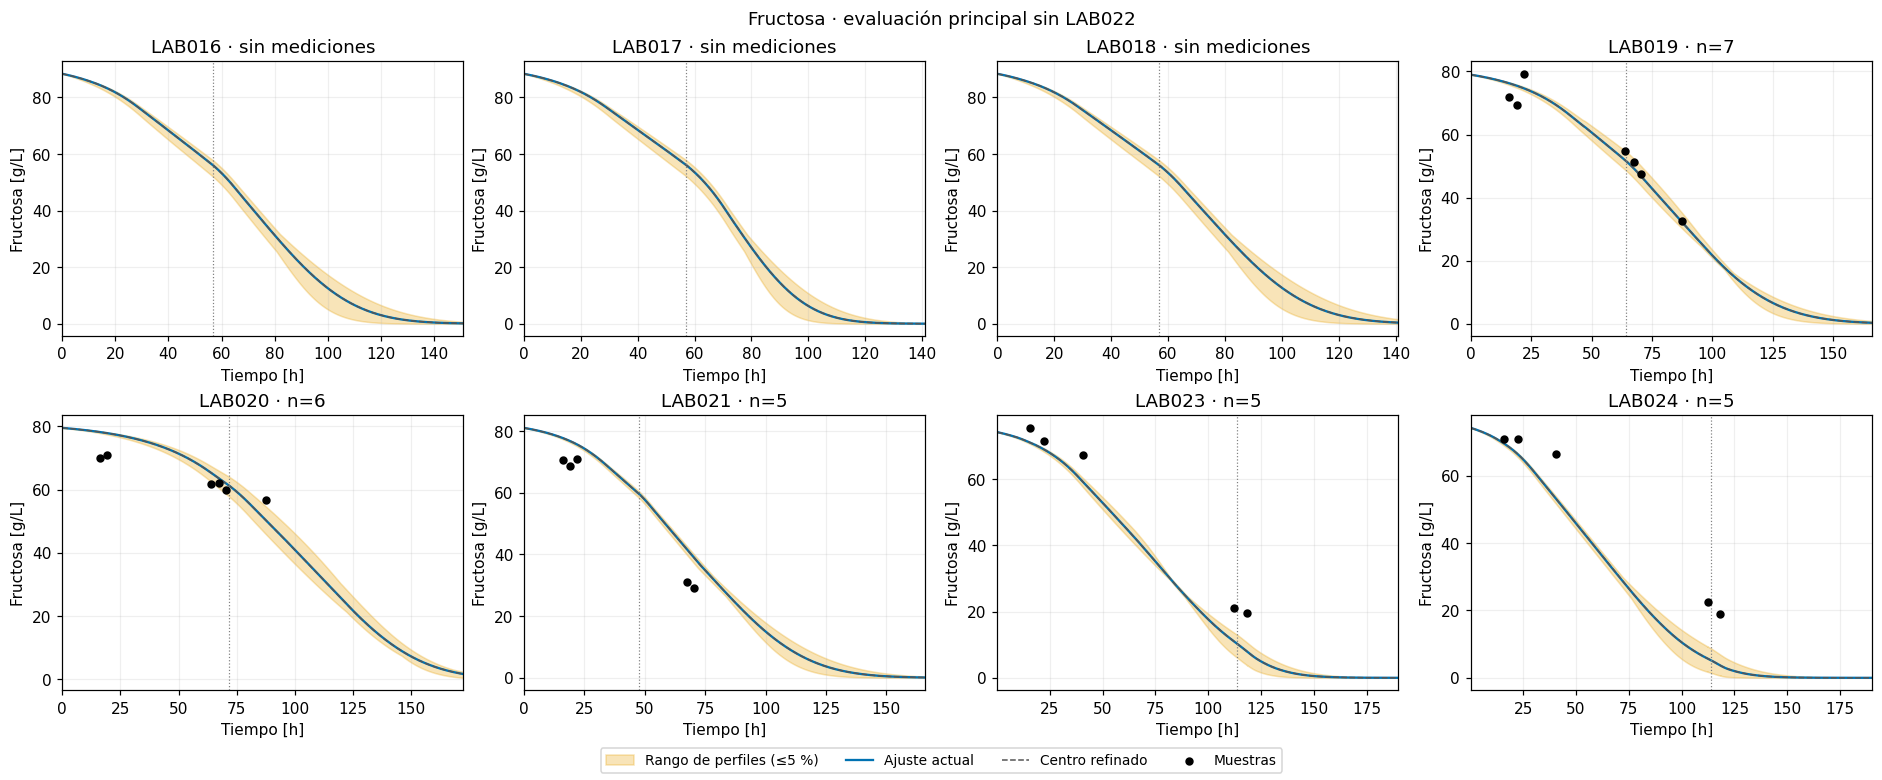

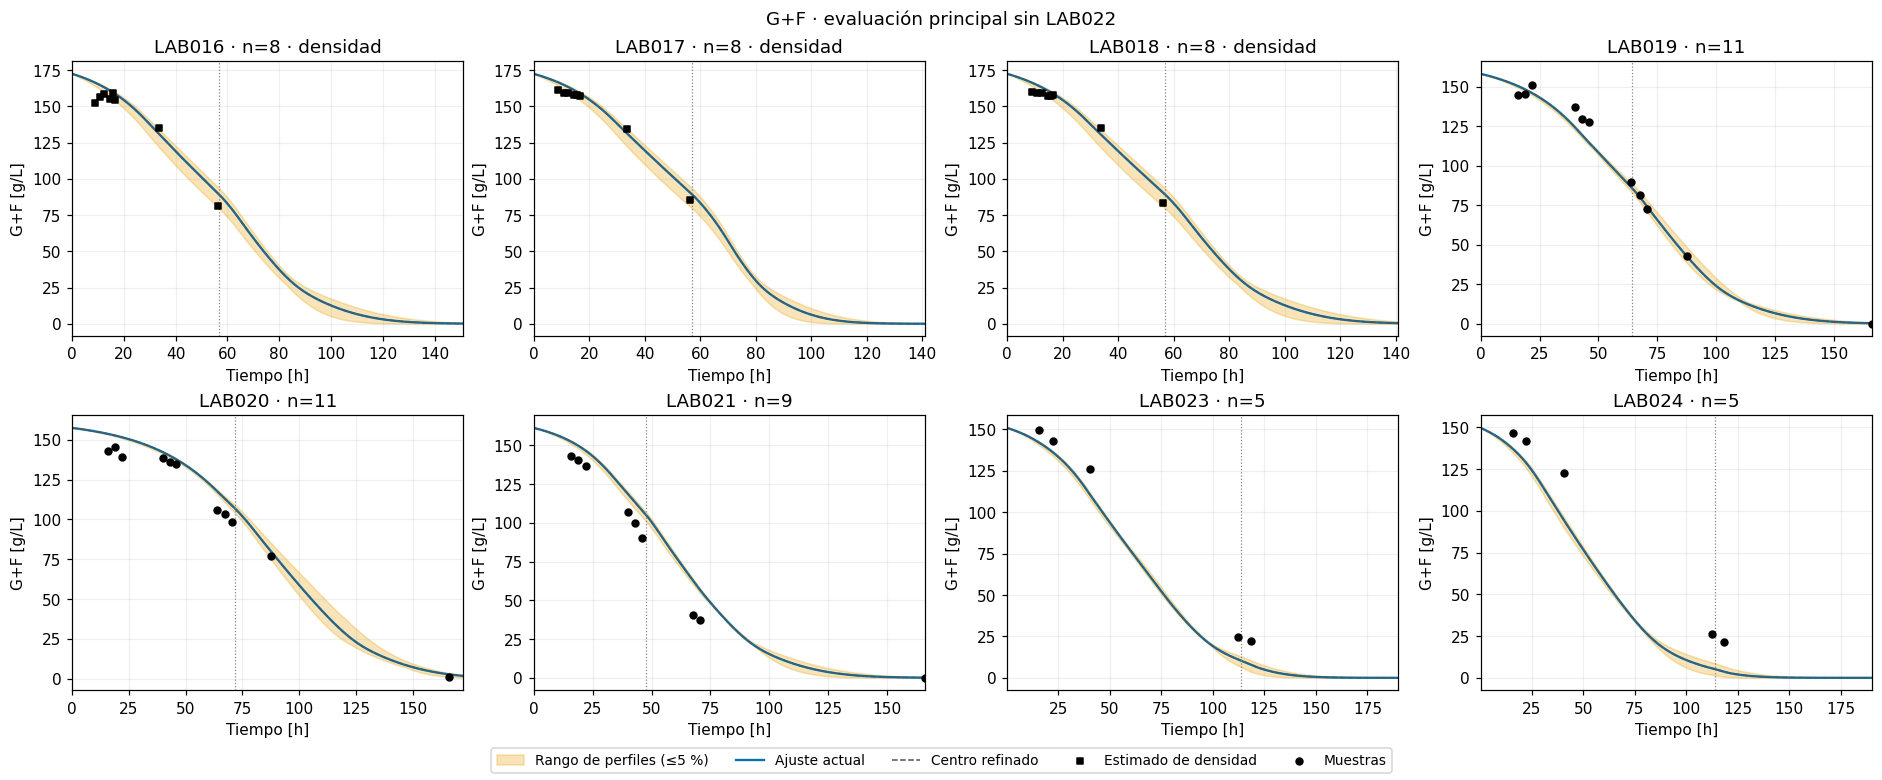

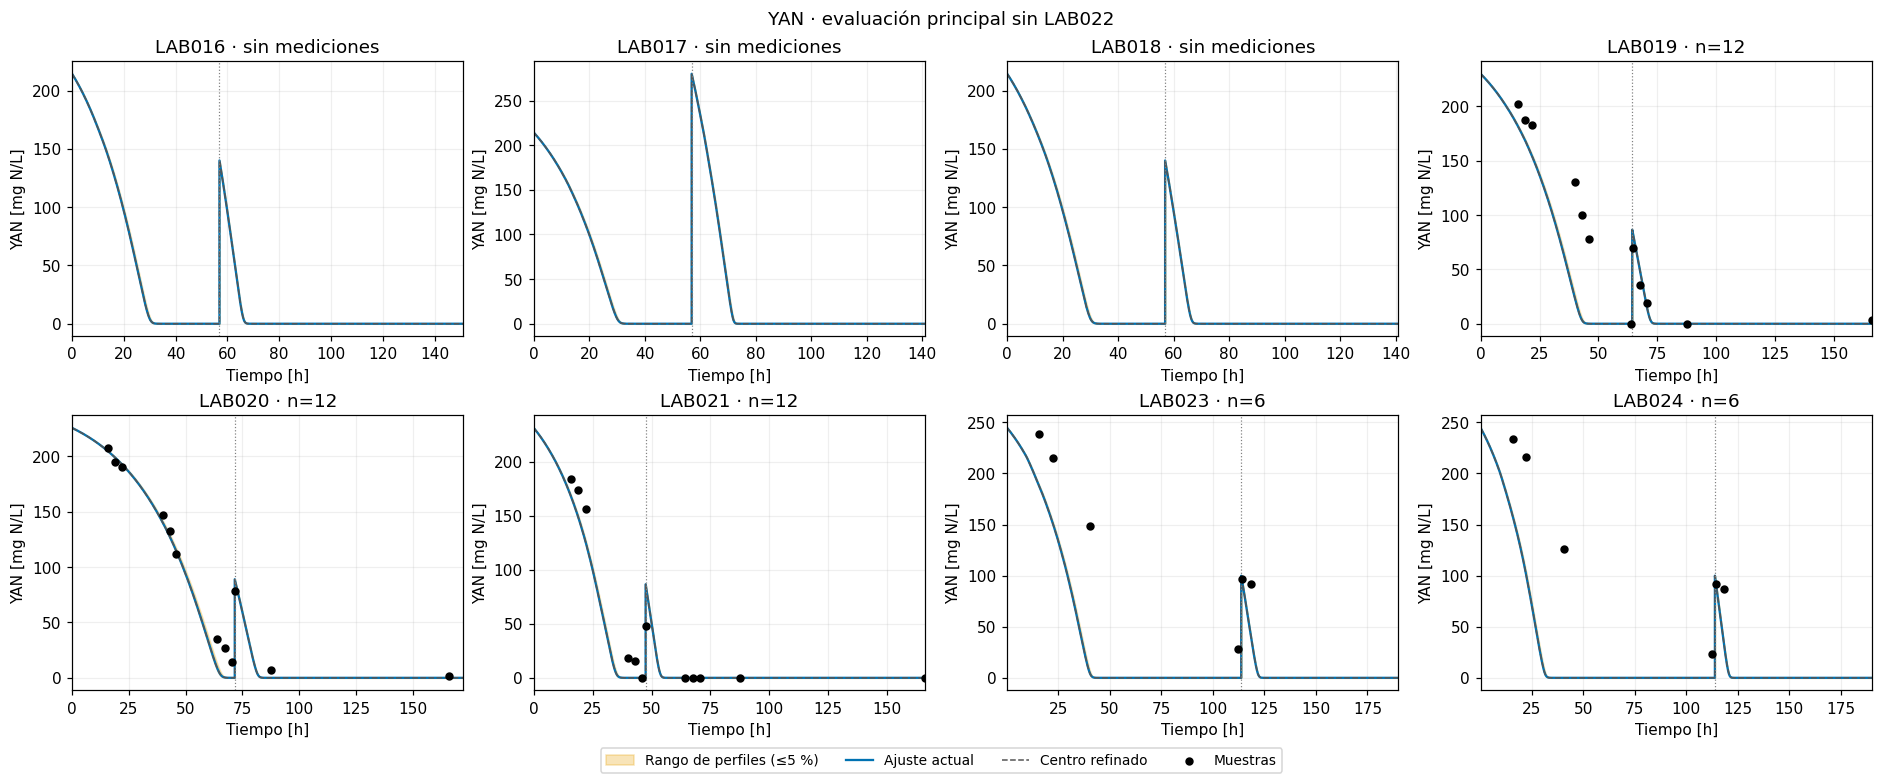

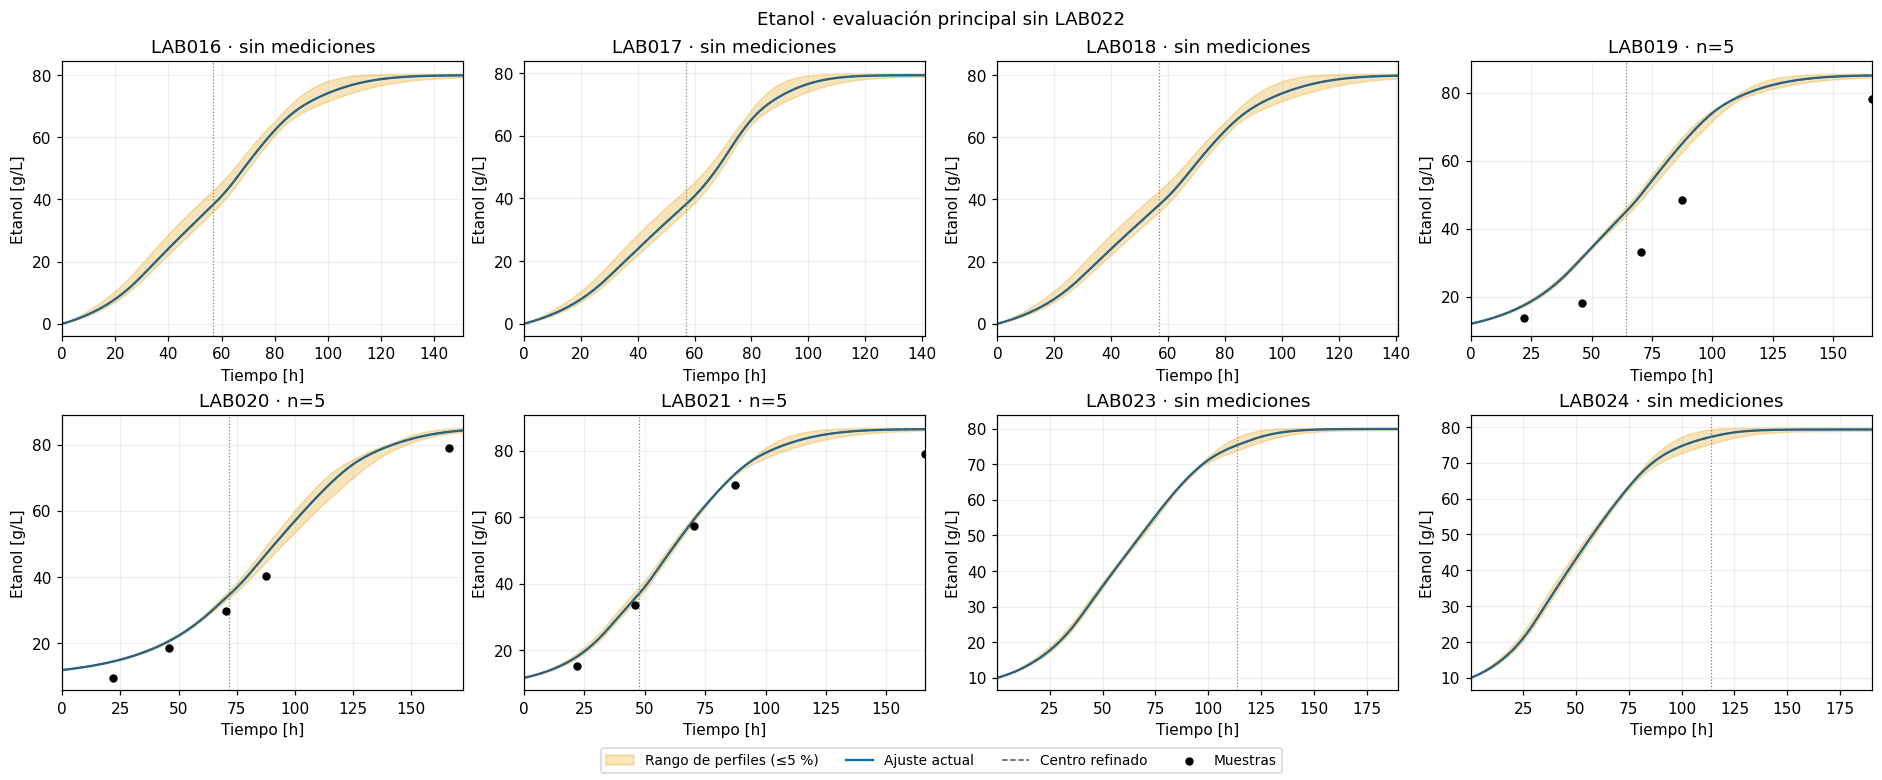

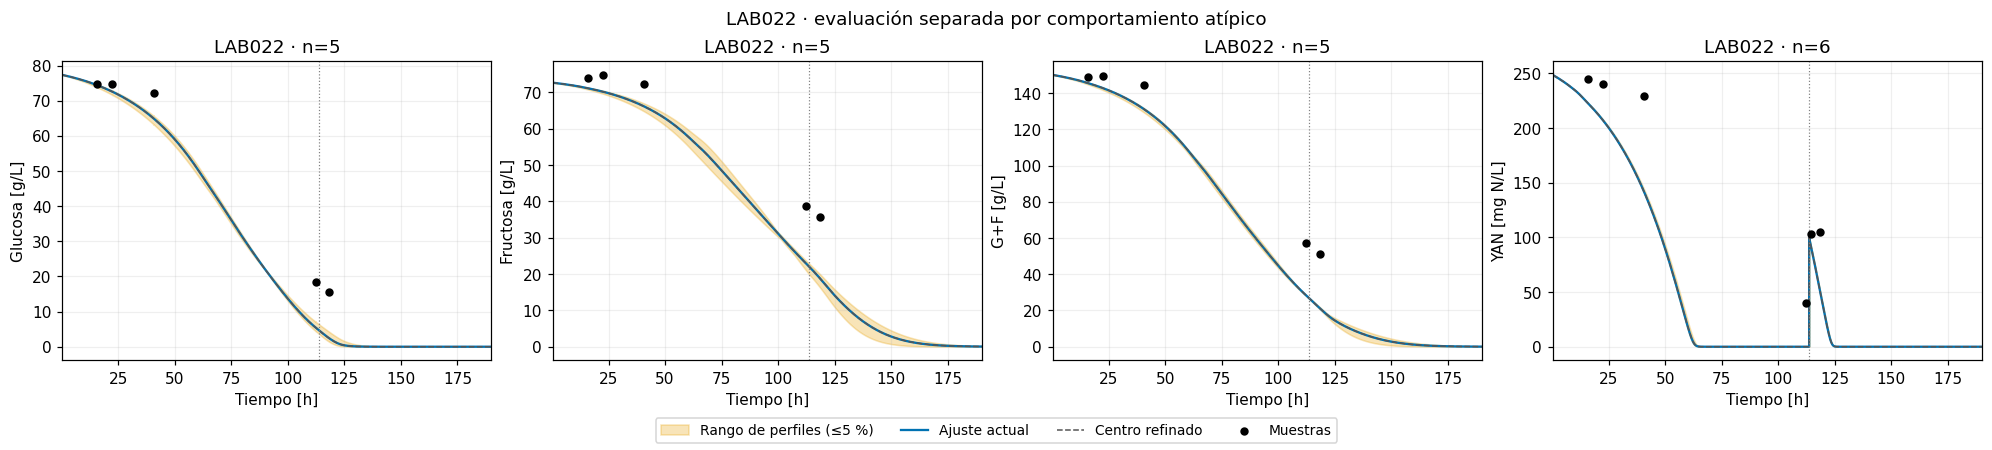

In [15]:
def validation_panel(ax,lab,state):
    profile_names=[name for name in validation_parameters if name!="Actual"]
    frames={name:setup["with_jumps"](validation_curves[name][lab]) for name in validation_parameters}
    reference=frames["Actual"]
    assert all(np.array_equal(reference.index,f.index) for f in frames.values())
    factor=VARS[state][2]
    matrix=np.vstack([frames[name][state].to_numpy()*factor for name in profile_names])
    ax.fill_between(reference.index,matrix.min(axis=0),matrix.max(axis=0),color="#E69F00",alpha=.28,label="Rango de perfiles (≤5 %)")
    ax.plot(reference.index,reference[state]*factor,color="#0072B2",lw=1.5,label="Ajuste actual")
    ax.plot(frames["Centro"].index,frames["Centro"][state]*factor,color="#555555",ls="--",lw=1,label="Centro refinado")
    obs=validation_observations[lab,state]
    proxy=lab in ("LAB016","LAB017","LAB018") and state=="GF"
    ax.scatter(obs.index,obs.values,c="black",s=20,zorder=5,marker="s" if proxy else "o",
               label="Estimado de densidad" if proxy else "Muestras")
    for t,_ in batches[lab].pulses["N"]: ax.axvline(t,c="gray",ls=":",lw=.8)
    title=lab+(" · sin mediciones" if obs.empty else f" · n={len(obs)}")
    if proxy: title+=" · densidad"
    ax.set(title=title,xlabel="Tiempo [h]",ylabel=f"{VARS[state][0]} [{VARS[state][1]}]",xlim=(reference.index[0],reference.index[-1]))
    ax.grid(alpha=.2)

for state in validation_states:
    if not any(len(validation_observations[lab,state]) for lab in validation_main): continue
    fig,axes=plt.subplots(2,4,figsize=(17,7),layout="constrained")
    for ax,lab in zip(axes.flat,validation_main): validation_panel(ax,lab,state)
    legend_entries={}
    for ax in axes.flat:
        handles,labels=ax.get_legend_handles_labels()
        legend_entries.update(zip(labels,handles))
    fig.legend(legend_entries.values(),legend_entries.keys(),loc="outside lower center",ncol=len(legend_entries),fontsize=9)
    fig.suptitle(f"{VARS[state][0]} · evaluación principal sin LAB022")
    plt.show()

states_022=[state for state in validation_states if len(validation_observations["LAB022",state])]
fig,axes=plt.subplots(1,len(states_022),figsize=(4.5*len(states_022),4),layout="constrained",squeeze=False)
for ax,state in zip(axes.flat,states_022): validation_panel(ax,"LAB022",state)
handles,labels=axes.flat[0].get_legend_handles_labels()
fig.legend(handles,labels,loc="outside lower center",ncol=4,fontsize=9)
fig.suptitle("LAB022 · evaluación separada por comportamiento atípico")
plt.show()


## Interpretación de la evaluación química

Las diferencias entre conjuntos se valoran por variable y fermentación, junto con su cobertura. Una banda estrecha indica predicciones similares pese a los cambios de parámetros. Una banda amplia indica que los conjuntos se separan en esa variable; las mediciones pueden aportar información para discriminar entre ellos si sus diferencias superan la incertidumbre experimental y los errores comunes del modelo.

Un error menor en esta evaluación aporta evidencia comparativa a favor de un conjunto dentro de los candidatos explorados. No demuestra por sí solo que sus parámetros sean únicos o físicamente correctos. LAB022 y las estimaciones basadas en densidad no se utilizan para decidir por sí solos. Los resultados se limitan a las muestras, los horizontes, las condiciones iniciales y las entradas conservadas del 16_3. Una vez utilizados para seleccionar parámetros, estos lotes dejan de ser una validación independiente de esa selección.

## Resultados de esta evaluación química

Se comparan el ajuste actual y 13 conjuntos distintos de los perfiles, incluido el centro refinado. Los conjuntos seleccionados conservan el objetivo de LAB004–009 dentro de un aumento de 5 %. No se reajustan con los datos de evaluación.

En LAB016–018 hay ocho referencias de azúcar total por fermentación, estimadas de densidad y limitadas aproximadamente a las primeras 56 horas. En el soporte utilizado no hay determinaciones químicas de glucosa, fructosa, YAN o etanol para esos tres lotes. La comparación química principal utiliza LAB019–021 y LAB023–024. El etanol solo tiene mediciones en LAB019–021. LAB022 se evalúa aparte.

| Variable y unidad | Muestras del grupo principal | RMSE del ajuste actual | Menor–mayor RMSE de los perfiles |
|---|---:|---:|---:|
| Glucosa [g/L] | 30 | 6,39 | 6,24–6,83 |
| Fructosa [g/L] | 28 | 7,70 | 7,41–8,69 |
| Azúcar total [g/L] | 41 | 11,64 | 11,26–12,42 |
| YAN [mg N/L] | 48 | 46,61 | 45,70–46,94 |
| Etanol [g/L] | 15 | 8,21 | 7,69–8,90 |

Los conjuntos producen predicciones cercanas en general, aunque existe separación en algunos tramos de consumo de azúcar. Ninguno obtiene el menor error en todas las variables. El menor RMSE de glucosa corresponde al perfil con Kie0 = 1000 g/L; los de fructosa y azúcar total químico, al perfil con Kig0 = 1000 g/L; el de YAN, al perfil con Kie0 = 40 g/L; y el de etanol, al perfil con Kig0 = 20,2641 g/L. Estas referencias identifican conjuntos completos reajustados: las demás constantes y tasas también cambian. No son pruebas del efecto aislado de una constante.

El YAN discrimina poco entre estos conjuntos. En LAB023 y LAB024, por ejemplo, el RMSE actual es aproximadamente 71,9 y 80,4 mg N/L, mientras que los perfiles recorren 70,6–72,3 y 79,3–80,7 mg N/L. Los cambios de las constantes y tasas explorados apenas resuelven las discrepancias comunes con las mediciones. Este resultado no determina por sí solo su causa.

En LAB022, el RMSE de azúcar total del ajuste actual es 19,82 g/L y el de los perfiles recorre 19,83–20,18 g/L. La discrepancia permanece para todos los conjuntos y no decide la comparación del grupo principal. La referencia indirecta de densidad de LAB016–018 favorece otros conjuntos: su RMSE agregado es 5,62 g/L en el ajuste actual y 4,96–6,83 g/L entre perfiles. Se conserva separada por su origen y cobertura.

La evaluación aporta información sobre las diferencias de predicción, pero no resuelve la compensación de parámetros ni identifica un conjunto claramente preferible en todas las variables. No justifica sustituir automáticamente el ajuste actual por uno de los perfiles. La biomasa medida no interviene en estos errores; la biomasa inicial y las demás entradas se conservan como en 16_3, por lo que sus limitaciones siguen formando parte del alcance de la comparación.


## Muerte celular durante la formación de biomasa y el consumo de YAN

Se estudia el vector calibrado principal, sin reajustarlo. El análisis se concentra en LAB004–009 porque sus mediciones determinan el rendimiento de biomasa respecto al nitrógeno. Se mantienen las condiciones iniciales, los perfiles térmicos y las nutriciones. El coeficiente de referencia de muerte permanece fijo en 0,00044 h⁻¹; la muerte efectiva se calcula con la ley original, que depende de temperatura, etanol y umbral térmico.

Se añaden dos contadores a los balances químicos: biomasa formada acumulada y biomasa muerta acumulada. No son estados nuevos que modifiquen la química:

\[
B(t)=\int_{t_0}^t\mu X\,dt,\qquad D(t)=\int_{t_0}^t k_dX\,dt.
\]
\[
X(t)-X_0=B(t)-D(t),\qquad B(t)=Y_{XN}\left[N_0+\sum_{t_j<t}\Delta N_j-N(t)\right].
\]

Las muestras en la hora exacta de una nutrición representan el estado previo al salto. Se verifica el cierre numérico de ambas identidades y la concordancia con el simulador original. La integración de diagnóstico utiliza tolerancias estrictas y pasos máximos de 0,1 y 0,05 h para comprobar estabilidad.

La ventana principal termina al alcanzar el 99 % de la formación acumulada de biomasa de cada lote. Es una definición operativa basada en la trayectoria, no en el último muestreo. Además, se integra por separado la muerte mientras el YAN del modelo es al menos 1 mg N/L y 20 mg N/L. Así se distingue la pérdida durante el crecimiento de la pérdida posterior. El umbral de 20 mg N/L permite comparar con el tratamiento de las observaciones de YAN de la calibración; los cálculos usan el YAN continuo del modelo.

Se simula también el caso sin muerte, manteniendo todos los parámetros y entradas. Este contraste aísla el efecto de la mortalidad supuesta; no es una nueva calibración ni una estimación de la mortalidad real.

Para dimensionar la compensación propuesta se calcula, hasta el 99 % de formación, la muerte que haría falta con rendimientos hipotéticos de 10 y 20 g biomasa/g N, conservando el nitrógeno consumido y el incremento neto de biomasa de la predicción actual:
\[
D_{\mathrm{requerida}}=Y_{XN}^{\mathrm{hipotético}}\,N_{\mathrm{consumido}}-(X-X_0).
\]
Estos valores son referencias contables, no parámetros recomendados ni simulaciones recalibradas. El rendimiento calibrado ya relaciona el nitrógeno consumido con la formación bruta; no se debe sumar la muerte una segunda vez al interpretarlo.


La condición de activación térmica impone \(k_d=0\) si \(T<T_D(E)\); los coeficientes y la función de umbral se conservan exactamente como en el modelo original.

In [16]:
mortality_model="GF"
mortality_parameters=theta.copy()
mortality_context={**setup,"solve_ivp":integrate_sugar_events}
exec(compile(simulate_source.replace(old_guard,new_guard),"16_3_mortality_reference","exec"),mortality_context)
mortality_reference=mortality_context["simulate"]
from dataclasses import replace
from scipy.integrate import solve_ivp as mortality_solve_ivp

mortality_step = 0.1  # h; malla de diagnóstico, sin modificar entradas ni parámetros.
mortality_training = {b.batch:b for b in treated} if mortality_model == "S" else training
assert set(mortality_training)=={f"LAB{i:03}" for i in range(4,10)}
mortality_physical = ["X","N","G","F","E"] if mortality_model=="GF" else ["X","N","S","E"]
mortality_sugars = (2,3) if mortality_model=="GF" else (2,)

def mortality_rhs(batch, parameters, no_death=False):
    def rhs(t,state):
        y=state[:len(mortality_physical)].copy()
        x=max(float(y[0]),0.)
        if mortality_model=="GF":
            q=kin.kinetic_terms(parameters,kin.temperature_at(batch,t),*y)
            mu=q["mu"] if any(y[i]>0 for i in mortality_sugars) else 0.
            kd=q["kd"]
            dy=np.asarray(kin.rhs(t,y,parameters,batch)).copy()
            growth=q["mu"]*x
            if y[2]<=0 or y[3]<=0:
                if y[2]<=0 and y[3]<=0:
                    dy[0]-=growth;dy[1]+=growth/parameters["Yxn"]
                if y[2]<=0:dy[2]+=growth/parameters["Yxg"]
                if y[3]<=0:dy[3]+=growth/parameters["Yxf"]
        else:
            mu,beta,kd,maintenance=terms_s(t,y,parameters,batch)
            dy=np.array([(mu-kd)*x,-mu*x/parameters["Yxn"],
                         -(mu/YXS+beta/parameters["Yes"]+maintenance)*x,beta*x])
        if no_death:dy[0]+=kd*x;kd=0.
        for index in mortality_sugars:
            if y[index]<=0:dy[index]=0.
        # Integrales de formación y muerte; los últimos dos contadores separan
        # la muerte mientras N es al menos 1 y 20 mg N/L, respectivamente.
        birth=mu*x;death=kd*x
        return np.r_[dy,birth,death,death if y[1]>=.001 else 0.,death if y[1]>=.020 else 0.]
    return rhs

def mortality_integrate(batch, parameters, no_death=False, step=mortality_step):
    number=len(mortality_physical)
    initial=[batch.initials[k] for k in (mortality_physical if mortality_model=="GF" else ["X","N"])]
    if mortality_model=="S":initial += [batch.initials["G"]+batch.initials["F"],batch.initials["E"]]
    state=np.r_[initial,np.zeros(4)]
    start=float(batch.time[0]);finish=float(batch.time[-1]);now=start
    times=np.unique(np.r_[np.arange(start,finish,step),batch.time,finish])
    doses={}
    for t,d in batch.pulses.get("N",()):
        if start<t<=finish:doses[float(t)]=doses.get(float(t),0.)+d
    records={start:state.copy()};jumps=[]
    original_rhs=mortality_rhs(batch,parameters,no_death)
    for end in sorted(set([finish,*doses])):
        while now<end:
            active=[i for i in mortality_sugars if state[i]>0]
            frozen=[i for i in mortality_sugars if i not in active]
            def rhs(t,y):
                physical=y.copy()
                physical[active]=np.maximum(physical[active],np.finfo(float).tiny)
                physical[frozen]=0.
                derivative=original_rhs(t,physical)
                derivative[frozen]=0.
                return derivative
            events=[]
            for index in active:
                def depletion(t,y,index=index):return y[index]
                depletion.terminal=True;depletion.direction=-1
                events.append(depletion)
            sol=mortality_solve_ivp(rhs,(now,end),state,method="LSODA",dense_output=True,
                events=events or None,rtol=2e-8,atol=2e-10,max_step=step)
            assert sol.success and np.isfinite(sol.y).all(),sol.message
            stop=float(sol.t[-1])
            requested=times[(times>now)&(times<=stop)]
            if len(requested):records.update({float(t):y.copy() for t,y in zip(requested,sol.sol(requested).T)})
            state=sol.y[:,-1].copy()
            if sol.status==1:
                hit=[i for i,hits in enumerate(sol.t_events) if len(hits)]
                assert len(hit)==1
                state[active[hit[0]]]=0.
            assert stop>now
            records[stop]=state.copy();now=stop
        if end in doses:
            before=state.copy();state[1]+=doses[end]
            jumps.append((end,before,state.copy()))
    frame=pd.DataFrame.from_dict(records,orient="index",columns=mortality_physical+["Formada","Muerta","Muerta_N1","Muerta_N20"]).sort_index()
    assert frame[mortality_physical].to_numpy().min()>-1e-6
    frame[mortality_physical]=frame[mortality_physical].clip(lower=0.)
    # Las filas en la hora exacta de una nutrición representan el estado previo.
    received=np.array([sum(d for t,d in doses.items() if t<time) for time in frame.index])
    uptake=batch.initials["N"]+received-frame.N.to_numpy()
    n_error=np.max(np.abs(uptake-frame.Formada.to_numpy()/parameters["Yxn"]))
    x_error=np.max(np.abs(frame.X.to_numpy()-initial[0]-frame.Formada.to_numpy()+frame.Muerta.to_numpy()))
    assert n_error<2e-6 and x_error<2e-6,(batch.batch,n_error,x_error)
    frame.attrs.update(jumps=jumps,n_balance_error=n_error,x_balance_error=x_error)
    return frame

mortality_curves={};mortality_without_death={};mortality_rows=[];mortality_checks=[]
for lab,batch in mortality_training.items():
    frame=mortality_integrate(batch,mortality_parameters)
    counter=mortality_integrate(batch,mortality_parameters,no_death=True)
    mortality_curves[lab]=frame;mortality_without_death[lab]=counter
    reference=(mortality_reference(batch,mortality_parameters))
    errors=np.abs(frame.loc[reference.index,mortality_physical].to_numpy()-reference[mortality_physical].to_numpy())
    assert errors.max()<5e-4,(lab,errors.max())
    total_birth=float(frame.Formada.iloc[-1]);assert total_birth>0
    t99=float(np.interp(.99*total_birth,frame.Formada,frame.index))
    birth99=float(np.interp(t99,frame.index,frame.Formada))
    dead99=float(np.interp(t99,frame.index,frame.Muerta))
    uptake99=birth99/mortality_parameters["Yxn"]
    net99=birth99-dead99
    kd_values=[];kd_with_n=[];death_times=[]
    for t,row in frame.iterrows():
        if mortality_model=="GF":kd=kin.kinetic_terms(mortality_parameters,kin.temperature_at(batch,t),*row[mortality_physical])["kd"]
        else:kd=terms_s(t,row[mortality_physical].to_numpy(),mortality_parameters,batch)[2]
        kd_values.append(kd)
        if row.N>=.001:kd_with_n.append(kd)
        if kd>0:death_times.append(t)
    dead=float(frame.Muerta.iloc[-1])
    no_death_x=np.interp(frame.index,counter.index,counter.X)
    no_death_n=np.interp(frame.index,counter.index,counter.N)
    mortality_rows.append({"LAB":lab,"Horizonte [h]":frame.index[-1],"99 % de formación [h]":t99,
        "Biomasa formada total [g/L]":total_birth,"Muerte hasta 99 % [g/L]":dead99,
        "Muerte/formación hasta 99 % [%]":100*dead99/birth99,
        "Muerte con YAN ≥1 mg N/L [g/L]":float(frame.Muerta_N1.iloc[-1]),
        "Muerte con YAN ≥20 mg N/L [g/L]":float(frame.Muerta_N20.iloc[-1]),
        "Muerte total [g/L]":dead,"Muerte posterior al 99 % [g/L]":dead-dead99,
        "Primera activación de muerte [h]":min(death_times) if death_times else np.nan,
        "Máximo kd con YAN ≥1 mg N/L [1/h]":max(kd_with_n,default=0.),"Máximo kd [1/h]":max(kd_values),
        "YAN consumido hasta 99 % [mg N/L]":1000*uptake99,
        "Rendimiento neto hasta 99 % [g/g]":net99/uptake99,
        "Muerte requerida para YXN=10 hasta 99 % [g/L]":10*uptake99-net99,
        "Muerte requerida para YXN=20 hasta 99 % [g/L]":20*uptake99-net99,
        "Máxima diferencia X sin muerte [g/L]":float(np.max(np.abs(no_death_x-frame.X))),
        "Máxima diferencia YAN sin muerte [mg N/L]":float(1000*np.max(np.abs(no_death_n-frame.N)))})
    mortality_checks.append({"LAB":lab,"Δ máximo vs simulador original [g/L]":errors.max(),
        "Error balance X [g/L]":frame.attrs["x_balance_error"],"Error balance N [g/L]":frame.attrs["n_balance_error"]})
    print("Diagnóstico de muerte completado:",lab,flush=True)
mortality_summary=pd.DataFrame(mortality_rows).set_index("LAB")
mortality_checks=pd.DataFrame(mortality_checks).set_index("LAB")
display(mortality_summary[["99 % de formación [h]","Biomasa formada total [g/L]","Muerte hasta 99 % [g/L]",
    "Muerte/formación hasta 99 % [%]","Muerte con YAN ≥1 mg N/L [g/L]","Muerte total [g/L]","Muerte posterior al 99 % [g/L]"]].round(6))
display(mortality_summary[["Primera activación de muerte [h]","Máximo kd con YAN ≥1 mg N/L [1/h]","Máximo kd [1/h]",
    "Muerte con YAN ≥20 mg N/L [g/L]","Máxima diferencia X sin muerte [g/L]","Máxima diferencia YAN sin muerte [mg N/L]"]].round(6))
display(mortality_summary[["YAN consumido hasta 99 % [mg N/L]","Rendimiento neto hasta 99 % [g/g]",
    "Muerte requerida para YXN=10 hasta 99 % [g/L]","Muerte requerida para YXN=20 hasta 99 % [g/L]"]].round(6))
display(mortality_checks)
# Comprobar estabilidad del diagnóstico al reducir a la mitad el paso máximo.
mortality_step_checks=[]
for lab,batch in mortality_training.items():
    fine=mortality_integrate(batch,mortality_parameters,step=mortality_step/2)
    base=mortality_curves[lab]
    difference=(fine.iloc[-1]-base.iloc[-1]).abs()
    assert difference[["X","N","Formada","Muerta","Muerta_N1","Muerta_N20"]].max()<2e-4
    mortality_step_checks.append({"LAB":lab,"Δ X final [g/L]":difference.X,"Δ muerte total [g/L]":difference.Muerta,
        "Δ muerte con YAN ≥1 mg N/L [g/L]":difference.Muerta_N1})
display(pd.DataFrame(mortality_step_checks).set_index("LAB"))
print("RESULTADOS MUERTE CELULAR",mortality_summary.to_json(orient="index",force_ascii=False))


Diagnóstico de muerte completado: LAB004
Diagnóstico de muerte completado: LAB005
Diagnóstico de muerte completado: LAB006
Diagnóstico de muerte completado: LAB007
Diagnóstico de muerte completado: LAB008
Diagnóstico de muerte completado: LAB009
RESULTADOS MUERTE CELULAR {"LAB004":{"Horizonte [h]":163.0,"99 % de formación [h]":75.6476300438,"Biomasa formada total [g\/L]":1.6384410793,"Muerte hasta 99 % [g\/L]":0.0,"Muerte\/formación hasta 99 % [%]":0.0,"Muerte con YAN ≥1 mg N\/L [g\/L]":0.0,"Muerte con YAN ≥20 mg N\/L [g\/L]":0.0,"Muerte total [g\/L]":0.1526576845,"Muerte posterior al 99 % [g\/L]":0.1526576845,"Primera activación de muerte [h]":105.5,"Máximo kd con YAN ≥1 mg N\/L [1\/h]":0.0,"Máximo kd [1\/h]":0.0015161353,"YAN consumido hasta 99 % [mg N\/L]":307.6524,"Rendimiento neto hasta 99 % [g\/g]":5.2723679987,"Muerte requerida para YXN=10 hasta 99 % [g\/L]":1.4544673315,"Muerte requerida para YXN=20 hasta 99 % [g\/L]":4.5309913315,"Máxima diferencia X sin muerte [g\/L]":0.15265

,99 % de formación [h],Biomasa formada total [g/L],Muerte hasta 99 % [g/L],Muerte/formación hasta 99 % [%],Muerte con YAN ≥1 mg N/L [g/L],Muerte total [g/L],Muerte posterior al 99 % [g/L]
LAB,,,,,,,
LAB004,75.647630,1.638441,0.0,0.0,0.0,0.152658,0.152658
LAB005,75.527927,1.620199,0.0,0.0,0.0,0.226441,0.226441
LAB006,109.359702,1.629794,0.0,0.0,0.0,0.103511,0.103511
LAB007,72.486863,1.682096,0.0,0.0,0.0,0.184161,0.184161
LAB008,72.639248,1.683045,0.0,0.0,0.0,0.138271,0.138271
LAB009,47.560001,1.673450,0.0,0.0,0.0,0.120225,0.120225


,Primera activación de muerte [h],Máximo kd con YAN ≥1 mg N/L [1/h],Máximo kd [1/h],Muerte con YAN ≥20 mg N/L [g/L],Máxima diferencia X sin muerte [g/L],Máxima diferencia YAN sin muerte [mg N/L]
LAB,,,,,,
LAB004,105.5,0.0,0.001516,0.0,0.152658,0.0
LAB005,98.9,0.0,0.002309,0.0,0.226441,0.0
LAB006,148.8,0.0,0.001097,0.0,0.103511,0.0
LAB007,98.0,0.0,0.001774,0.0,0.184161,0.0
LAB008,107.5,0.0,0.001548,0.0,0.138271,0.0
LAB009,94.1,0.0,0.000986,0.0,0.120225,0.0


,YAN consumido hasta 99 % [mg N/L],Rendimiento neto hasta 99 % [g/g],Muerte requerida para YXN=10 hasta 99 % [g/L],Muerte requerida para YXN=20 hasta 99 % [g/L]
LAB,,,,
LAB004,307.6524,5.272368,1.454467,4.530991
LAB005,304.2270,5.272368,1.438273,4.480543
LAB006,306.0288,5.272368,1.446792,4.507080
LAB007,315.8496,5.272368,1.493221,4.651717
LAB008,316.0278,5.272368,1.494063,4.654341
LAB009,314.2260,5.272368,1.485545,4.627805


,Δ máximo vs simulador original [g/L],Error balance X [g/L],Error balance N [g/L]
LAB,,,
LAB004,0.000293,4.607426e-15,7.771561e-16
LAB005,0.000210,3.469447e-15,7.771561e-16
LAB006,0.000164,3.191891e-15,3.330669e-16
LAB007,0.000055,3.869301e-15,4.996004e-16
LAB008,0.000198,1.908196e-15,6.661338e-16
LAB009,0.000079,2.886580e-15,4.440892e-16


,Δ X final [g/L],Δ muerte total [g/L],Δ muerte con YAN ≥1 mg N/L [g/L]
LAB,,,
LAB004,9.826285e-09,9.826282e-09,0.0
LAB005,1.266733e-07,1.266733e-07,0.0
LAB006,5.169276e-08,5.169276e-08,0.0
LAB007,1.193147e-07,1.193147e-07,0.0
LAB008,9.392034e-09,9.392032e-09,0.0
LAB009,6.692404e-09,6.692410e-09,0.0


## Formación acumulada y contraste sin muerte

Las líneas verticales grises indican las nutriciones. La zona sombreada termina al alcanzar el 99 % de la formación de biomasa. Las muestras de YAN son las transformadas y conservadas para la calibración; no se interpretan como un registro independiente sin tratamiento. La biomasa muerta acumulada es un contador calculado y no una medición experimental.

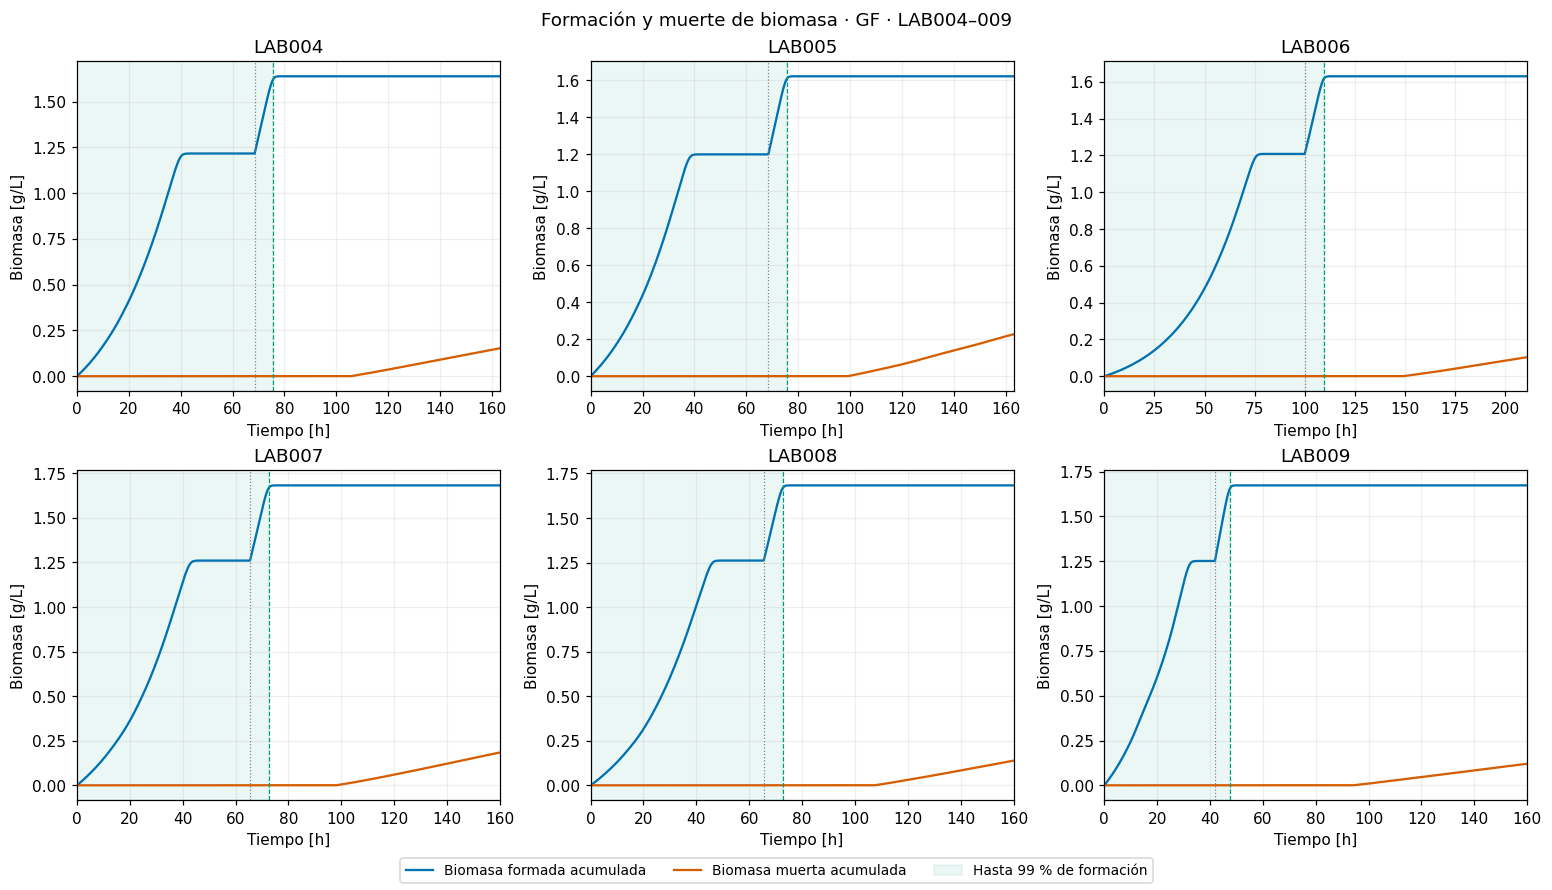

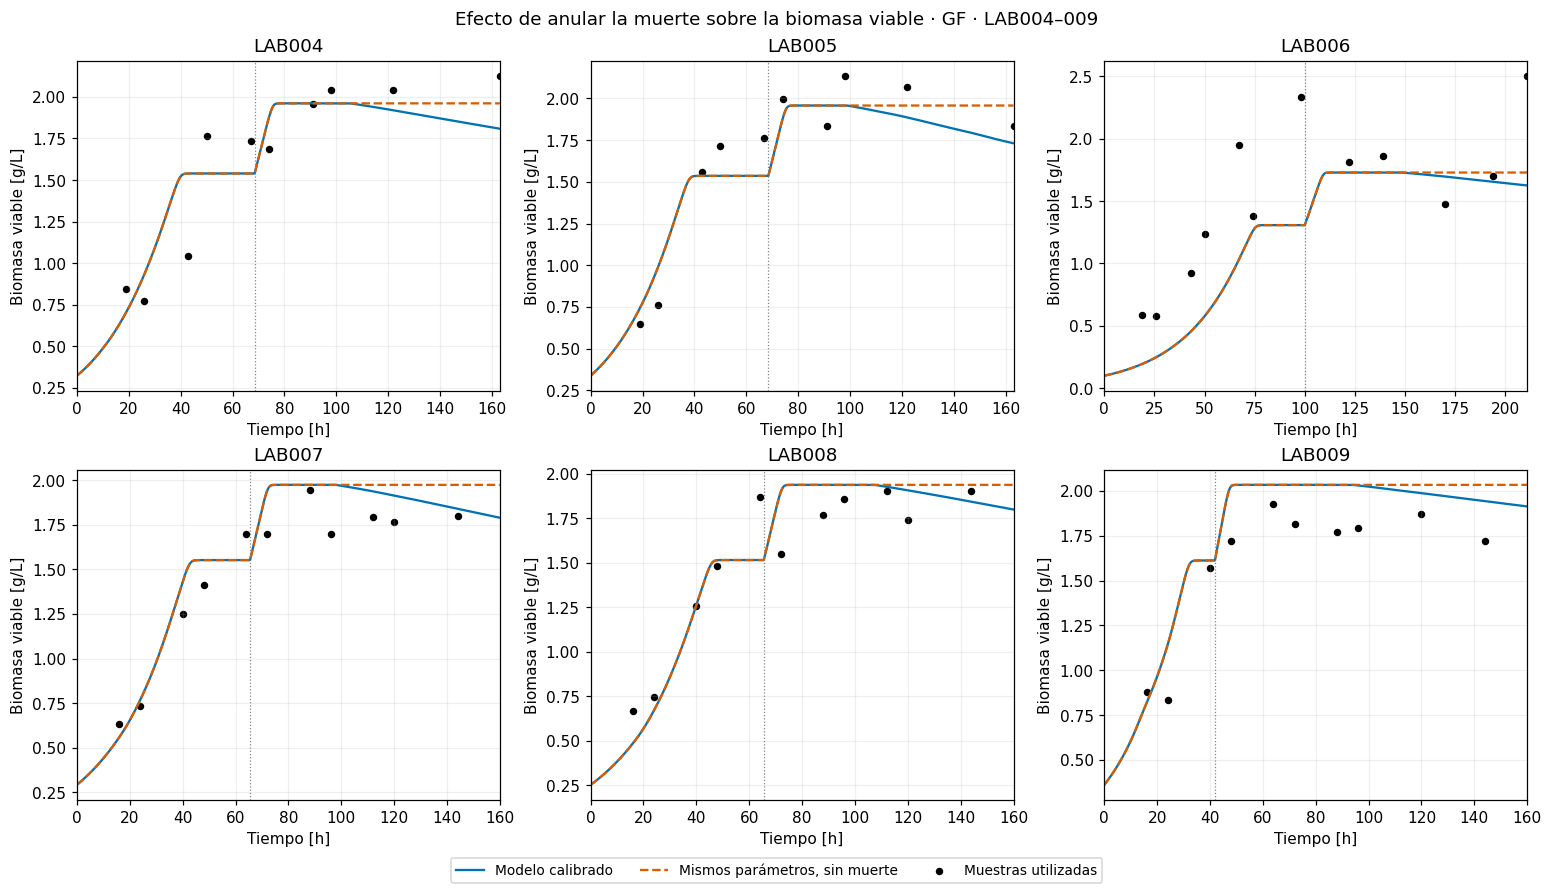

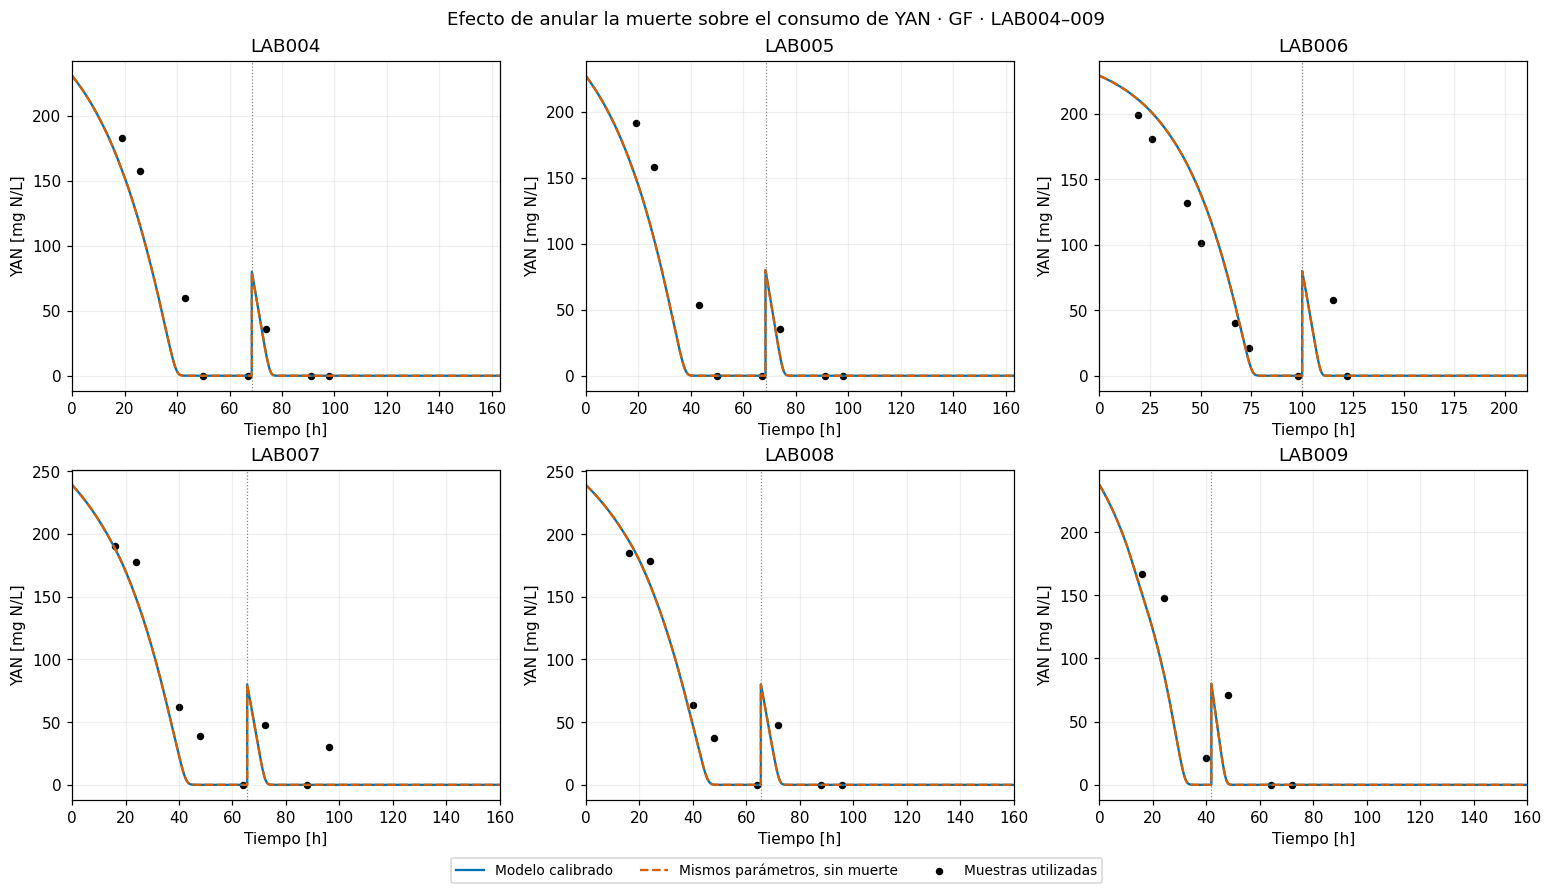

In [17]:
def mortality_plot_frame(frame):
    extra=[];times=[]
    for t,before,after in frame.attrs["jumps"]:
        extra.append(after);times.append(t)
    added=pd.DataFrame(extra,index=times,columns=frame.columns)
    return pd.concat([frame,added]).sort_index(kind="stable")

for variable in ("Acumuladas","X","N"):
    fig,axes=plt.subplots(2,3,figsize=(14,8),layout="constrained")
    for ax,(lab,batch) in zip(axes.flat,mortality_training.items()):
        frame=mortality_plot_frame(mortality_curves[lab]);counter=mortality_plot_frame(mortality_without_death[lab])
        t99=mortality_summary.at[lab,"99 % de formación [h]"]
        if variable=="Acumuladas":
            ax.plot(frame.index,frame.Formada,color="#0072B2",label="Biomasa formada acumulada")
            ax.plot(frame.index,frame.Muerta,color="#D55E00",label="Biomasa muerta acumulada")
            ax.axvspan(batch.time[0],t99,color="#009E73",alpha=.08,label="Hasta 99 % de formación")
            ax.axvline(t99,color="#009E73",ls="--",lw=.8)
            ax.set_ylabel("Biomasa [g/L]")
        else:
            factor=1000 if variable=="N" else 1
            ax.plot(frame.index,frame[variable]*factor,color="#0072B2",label="Modelo calibrado")
            ax.plot(counter.index,counter[variable]*factor,color="#D55E00",ls="--",label="Mismos parámetros, sin muerte")
            obs=batch.observations[variable];mask=np.isfinite(obs)&(batch.time>batch.time[0])
            ax.scatter(batch.time[mask],obs[mask]*factor,c="black",s=15,label="Muestras utilizadas")
            ax.set_ylabel("YAN [mg N/L]" if variable=="N" else "Biomasa viable [g/L]")
        for t,_ in batch.pulses["N"]:ax.axvline(t,color="gray",ls=":",lw=.8)
        ax.set(title=lab,xlabel="Tiempo [h]",xlim=(batch.time[0],batch.time[-1]));ax.grid(alpha=.2)
    handles,labels=axes.flat[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc="outside lower center",ncol=3,fontsize=9)
    title={"Acumuladas":"Formación y muerte de biomasa","X":"Efecto de anular la muerte sobre la biomasa viable","N":"Efecto de anular la muerte sobre el consumo de YAN"}[variable]
    fig.suptitle(title+f" · {mortality_model} · LAB004–009")
    plt.show()


## Resultado: alcance de la compensación entre mortalidad y rendimiento

En LAB004–009, la muerte integrada es cero hasta alcanzar el 99 % de la formación de biomasa. También es cero en las ventanas con YAN del modelo de al menos 1 mg N/L y 20 mg N/L. La mortalidad se activa posteriormente, cuando prácticamente todo el nitrógeno ya se ha consumido.

| Lote | 99 % de formación [h] | Primera muerte detectada [h] | Muerte hasta 99 % [g/L] | Muerte al final del lote [g/L] |
|---|---:|---:|---:|---:|
| LAB004 | 75,65 | 105,50 | 0,000000 | 0,153 |
| LAB005 | 75,53 | 98,90 | 0,000000 | 0,226 |
| LAB006 | 109,36 | 148,80 | 0,000000 | 0,104 |
| LAB007 | 72,49 | 98,00 | 0,000000 | 0,184 |
| LAB008 | 72,64 | 107,50 | 0,000000 | 0,138 |
| LAB009 | 47,56 | 94,10 | 0,000000 | 0,120 |

La primera muerte detectada se informa sobre una malla de como máximo 0,1 h; no es una medición experimental ni la localización exacta de la discontinuidad térmica. El horizonte final es el de cada lote original.

El caso con mortalidad anulada conserva las curvas de crecimiento durante el consumo apreciable de YAN y cambia la biomasa viable de la etapa posterior. La máxima diferencia de YAN entre ambos casos es inferior a 0,000001 mg N/L. Los balances integrados de biomasa y nitrógeno cierran con errores inferiores a 0,000002 g/L. La diferencia máxima entre el diagnóstico y el simulador original es 0.000293 g/L entre todos los estados; se conserva la química dentro de la tolerancia numérica declarada. La comprobación con paso de 0,05 h también satisface las tolerancias de estabilidad de la celda.

La comparación contable indica que, para adoptar un rendimiento de 10 g biomasa/g N manteniendo el nitrógeno consumido y la biomasa neta de la predicción actual hasta el 99 % de formación, haría falta perder aproximadamente **1.44–1.49 g/L** de biomasa en esa ventana. Eso equivale a cerca del **47.3 %** de la formación bruta hipotética; la ley actual predice **0 %** en esa misma ventana. Estos rendimientos hipotéticos sirven para dimensionar la diferencia, no para imponer valores de literatura como verdades del experimento.

**La mortalidad predicha actualmente no aporta la pérdida durante el crecimiento que sería necesaria para explicar un rendimiento bruto mucho mayor oculto tras una biomasa viable menor.** El rendimiento calibrado ya se aplica a la formación bruta de biomasa; no corresponde corregirlo sumando nuevamente la muerte. La pérdida tardía sí influye en las muestras finales de biomasa y puede influir indirectamente en un ajuste conjunto. Este contraste con parámetros fijos no cuantifica cuánto cambiaría el rendimiento al recalibrar otro modelo de mortalidad.

La ausencia de muerte temprana es una propiedad del modelo y sus trayectorias actuales, no una demostración de que no haya muerte real. La ley impone muerte cero por debajo del umbral térmico: aumentar solo su coeficiente de referencia no la activa mientras se conserve esa condición. Para investigar una compensación con mortalidad temprana habría que contrastar otra representación con datos de viabilidad o biomasa total y viable que la sustenten.

La revisión siguiente debe concentrarse en la relación observada entre incremento de biomasa y YAN consumido, la conversión de recuentos a masa, las condiciones iniciales, las nutriciones y el tratamiento de las lecturas de YAN. Este diagnóstico conserva todos los parámetros calibrados principales.
